# Section 1

In [2]:
# ============================================================
# NOTEBOOK 08 — DASHBOARD
# Section 1: Environment & Project Paths
# ============================================================

from pathlib import Path
import json
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Project root
# ------------------------------------------------------------
PROJECT_ROOT = Path("/content/drive/MyDrive/Major_Project")

# ------------------------------------------------------------
# Main directories
# ------------------------------------------------------------
DATASET_DIR = PROJECT_ROOT / "dataset"
MODELS_DIR = PROJECT_ROOT / "models"
EVALUATION_DIR = MODELS_DIR / "evaluation"
MITIGATION_DIR = PROJECT_ROOT / "mitigation"
NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"

# ------------------------------------------------------------
# Dashboard directory
# ------------------------------------------------------------
DASHBOARD_DIR = PROJECT_ROOT / "dashboard"
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Important Notebook 07 artifacts
# ------------------------------------------------------------
MITIGATION_RESULTS = MITIGATION_DIR / "final_mitigation_results.csv"
MITIGATION_SUMMARY = MITIGATION_DIR / "final_mitigation_summary.json"

# ------------------------------------------------------------
# Important Notebook 06 artifacts
# ------------------------------------------------------------
ANOMALYFLOW_CONFIG = EVALUATION_DIR / "anomalyflow_config.json"
ANOMALYFLOW_SUMMARY = EVALUATION_DIR / "anomalyflow_final_summary.json"

# ------------------------------------------------------------
# Model artifacts
# ------------------------------------------------------------
MODEL_PATH = MODELS_DIR / "hybrid_model.pth"
LABEL_ENCODER_PATH = MODELS_DIR / "label_encoder.pkl"
SCALER_PATH = MODELS_DIR / "scaler.pkl"

# ------------------------------------------------------------
# Display paths
# ------------------------------------------------------------
print("=" * 80)
print("NOTEBOOK 08 — DASHBOARD")
print("=" * 80)

print("\nProject Root:")
print(PROJECT_ROOT)

print("\nDashboard Directory:")
print(DASHBOARD_DIR)

print("\nRequired Notebook 07 Artifacts:")
print(" - Mitigation Results :", MITIGATION_RESULTS)
print(" - Mitigation Summary :", MITIGATION_SUMMARY)

print("\nRequired Notebook 06 Artifacts:")
print(" - AnomalyFlow Config  :", ANOMALYFLOW_CONFIG)
print(" - AnomalyFlow Summary :", ANOMALYFLOW_SUMMARY)

print("\nModel Artifacts:")
print(" - Model         :", MODEL_PATH)
print(" - Label Encoder :", LABEL_ENCODER_PATH)
print(" - Scaler        :", SCALER_PATH)

print("\n" + "=" * 80)
print("PATH VERIFICATION")
print("=" * 80)

paths_to_check = {
    "Project Root": PROJECT_ROOT,
    "Mitigation Results": MITIGATION_RESULTS,
    "Mitigation Summary": MITIGATION_SUMMARY,
    "AnomalyFlow Config": ANOMALYFLOW_CONFIG,
    "AnomalyFlow Summary": ANOMALYFLOW_SUMMARY,
    "Model": MODEL_PATH,
    "Label Encoder": LABEL_ENCODER_PATH,
    "Scaler": SCALER_PATH,
}

for name, path in paths_to_check.items():
    print(f"{name:<25}: {path.exists()}")

print("\nDashboard directory ready.")

NOTEBOOK 08 — DASHBOARD

Project Root:
/content/drive/MyDrive/Major_Project

Dashboard Directory:
/content/drive/MyDrive/Major_Project/dashboard

Required Notebook 07 Artifacts:
 - Mitigation Results : /content/drive/MyDrive/Major_Project/mitigation/final_mitigation_results.csv
 - Mitigation Summary : /content/drive/MyDrive/Major_Project/mitigation/final_mitigation_summary.json

Required Notebook 06 Artifacts:
 - AnomalyFlow Config  : /content/drive/MyDrive/Major_Project/models/evaluation/anomalyflow_config.json
 - AnomalyFlow Summary : /content/drive/MyDrive/Major_Project/models/evaluation/anomalyflow_final_summary.json

Model Artifacts:
 - Model         : /content/drive/MyDrive/Major_Project/models/hybrid_model.pth
 - Label Encoder : /content/drive/MyDrive/Major_Project/models/label_encoder.pkl
 - Scaler        : /content/drive/MyDrive/Major_Project/models/scaler.pkl

PATH VERIFICATION
Project Root             : True
Mitigation Results       : True
Mitigation Summary       : True
Ano

In [3]:
# ============================================================
# NOTEBOOK 08 — DASHBOARD
# Section 2: Load Final Mitigation Results
# ============================================================

print("=" * 80)
print("LOADING NOTEBOOK 07 MITIGATION RESULTS")
print("=" * 80)

# Load final sample-level mitigation results
mitigation_df = pd.read_csv(MITIGATION_RESULTS)

print("\nDataset loaded successfully.")

print("\nShape:")
print(mitigation_df.shape)

print("\nColumns:")
for i, column in enumerate(mitigation_df.columns, start=1):
    print(f"{i:02d}. {column}")

print("\nFirst 5 rows:")
display(mitigation_df.head())

print("\nData types:")
print(mitigation_df.dtypes)

print("\n" + "=" * 80)
print("BASIC VERIFICATION")
print("=" * 80)

print("\nExpected rows :", 338445)
print("Actual rows   :", len(mitigation_df))
print("Row count PASS:", len(mitigation_df) == 338445)

print("\nMissing values:")
print(mitigation_df.isnull().sum().sum())

print("\nDuplicate rows:")
print(mitigation_df.duplicated().sum())

LOADING NOTEBOOK 07 MITIGATION RESULTS

Dataset loaded successfully.

Shape:
(338445, 23)

Columns:
01. Test_Index
02. True_Label
03. Predicted_Label
04. Confidence
05. Confidence_Uncertainty
06. Renyi_Evidence
07. Confidence_Normalized
08. Renyi_Normalized
09. AnomalyFlow_Score
10. Decision_State
11. Security_Severity
12. Mitigation_Action
13. Mitigation_Priority
14. Mitigation_Simulation
15. Alert_Generated
16. Alert_Level
17. Alert_Type
18. Alert_Message
19. Simulated_Block
20. Simulated_Rate_Limit
21. Simulated_Monitoring
22. Simulated_Investigation
23. Mitigation_Outcome

First 5 rows:


,Test_Index,True_Label,Predicted_Label,Confidence,Confidence_Uncertainty,Renyi_Evidence,Confidence_Normalized,Renyi_Normalized,AnomalyFlow_Score,Decision_State,...,Mitigation_Simulation,Alert_Generated,Alert_Level,Alert_Type,Alert_Message,Simulated_Block,Simulated_Rate_Limit,Simulated_Monitoring,Simulated_Investigation,Mitigation_Outcome
0,0,NetBIOS,NetBIOS,0.274310,0.274310,0.417463,0.386017,0.056216,0.221116,NORMAL,...,DDoS alert generated and traffic event logged,True,LOW,DDOS_DETECTED,DDoS traffic detected with low AnomalyFlow evi...,False,False,False,False,ALERT_LOGGED
1,1,TFTP,TFTP,0.000000,0.000000,0.714693,0.000000,0.129823,0.064911,NORMAL,...,DDoS alert generated and traffic event logged,True,LOW,DDOS_DETECTED,DDoS traffic detected with low AnomalyFlow evi...,False,False,False,False,ALERT_LOGGED
2,2,Syn,Syn,0.000000,0.000000,1.309719,0.000000,0.277177,0.138588,NORMAL,...,DDoS alert generated and traffic event logged,True,LOW,DDOS_DETECTED,DDoS traffic detected with low AnomalyFlow evi...,False,False,False,False,ALERT_LOGGED
3,3,TFTP,TFTP,0.000000,0.000000,0.627796,0.000000,0.108303,0.054152,NORMAL,...,DDoS alert generated and traffic event logged,True,LOW,DDOS_DETECTED,DDoS traffic detected with low AnomalyFlow evi...,False,False,False,False,ALERT_LOGGED
4,4,DrDoS_SSDP,DrDoS_UDP,0.628116,0.628116,1.375605,0.883902,0.293493,0.588697,HIGH_EVIDENCE,...,Traffic blocking and rate limiting simulated,True,CRITICAL,BLOCK_TRIGGERED,High-evidence DDoS traffic detected; blocking ...,True,True,False,False,BLOCK_AND_RATE_LIMIT_SIMULATED



Data types:
Test_Index                   int64
True_Label                  object
Predicted_Label             object
Confidence                 float64
Confidence_Uncertainty     float64
Renyi_Evidence             float64
Confidence_Normalized      float64
Renyi_Normalized           float64
AnomalyFlow_Score          float64
Decision_State              object
Security_Severity           object
Mitigation_Action           object
Mitigation_Priority         object
Mitigation_Simulation       object
Alert_Generated               bool
Alert_Level                 object
Alert_Type                  object
Alert_Message               object
Simulated_Block               bool
Simulated_Rate_Limit          bool
Simulated_Monitoring          bool
Simulated_Investigation       bool
Mitigation_Outcome          object
dtype: object

BASIC VERIFICATION

Expected rows : 338445
Actual rows   : 338445
Row count PASS: True

Missing values:
0

Duplicate rows:
0


In [4]:
# ============================================================
# NOTEBOOK 08 — DASHBOARD
# Section 3: Load Project Summaries & Configuration
# ============================================================

print("=" * 80)
print("LOADING PROJECT SUMMARIES & ANOMALYFLOW CONFIGURATION")
print("=" * 80)

# ------------------------------------------------------------
# Load Notebook 07 mitigation summary
# ------------------------------------------------------------
with open(MITIGATION_SUMMARY, "r") as f:
    mitigation_summary = json.load(f)

# ------------------------------------------------------------
# Load Notebook 06 AnomalyFlow configuration
# ------------------------------------------------------------
with open(ANOMALYFLOW_CONFIG, "r") as f:
    anomalyflow_config = json.load(f)

# ------------------------------------------------------------
# Load Notebook 06 final summary
# ------------------------------------------------------------
with open(ANOMALYFLOW_SUMMARY, "r") as f:
    anomalyflow_summary = json.load(f)

print("\nMitigation summary loaded successfully.")
print("AnomalyFlow configuration loaded successfully.")
print("AnomalyFlow final summary loaded successfully.")

# ------------------------------------------------------------
# Display top-level keys
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("MITIGATION SUMMARY")
print("=" * 80)

print("\nTop-level keys:")
for key in mitigation_summary.keys():
    print(" -", key)

print("\n" + "=" * 80)
print("ANOMALYFLOW CONFIGURATION")
print("=" * 80)

print("\nConfiguration:")
print(json.dumps(anomalyflow_config, indent=2))

print("\n" + "=" * 80)
print("ANOMALYFLOW FINAL SUMMARY")
print("=" * 80)

print("\nTop-level keys:")
for key in anomalyflow_summary.keys():
    print(" -", key)

print("\n" + "=" * 80)
print("ARTIFACT VERIFICATION")
print("=" * 80)

print("\nMitigation Summary exists :", MITIGATION_SUMMARY.exists())
print("AnomalyFlow Config exists :", ANOMALYFLOW_CONFIG.exists())
print("AnomalyFlow Summary exists:", ANOMALYFLOW_SUMMARY.exists())

LOADING PROJECT SUMMARIES & ANOMALYFLOW CONFIGURATION

Mitigation summary loaded successfully.
AnomalyFlow configuration loaded successfully.
AnomalyFlow final summary loaded successfully.

MITIGATION SUMMARY

Top-level keys:
 - notebook
 - input_artifact
 - output_artifact
 - total_test_samples
 - mitigation_policy
 - alert_policy
 - security_severity_counts
 - mitigation_action_counts
 - alert_statistics
 - simulation_statistics
 - output_schema

ANOMALYFLOW CONFIGURATION

Configuration:
{
  "confidence_weight": 0.5,
  "renyi_weight": 0.5,
  "low_threshold": 0.25,
  "high_threshold": 0.4,
  "states": {
    "low": "NORMAL",
    "medium": "SUSPICIOUS",
    "high": "HIGH_EVIDENCE"
  }
}

ANOMALYFLOW FINAL SUMMARY

Top-level keys:
 - baseline_model
 - anomalyflow
 - decision_states
 - binary_ddos_detection
 - security_severity

ARTIFACT VERIFICATION

Mitigation Summary exists : True
AnomalyFlow Config exists : True
AnomalyFlow Summary exists: True


In [5]:
# ============================================================
# NOTEBOOK 08 — DASHBOARD
# Section 4: Dataset Integrity & Distribution Verification
# ============================================================

print("=" * 80)
print("DASHBOARD DATASET INTEGRITY & DISTRIBUTION VERIFICATION")
print("=" * 80)

# ------------------------------------------------------------
# Expected project values from Notebook 07
# ------------------------------------------------------------
EXPECTED_ROWS = 338_445

EXPECTED_DECISION_STATES = {
    "NORMAL": 270_361,
    "SUSPICIOUS": 37_300,
    "HIGH_EVIDENCE": 30_784,
}

EXPECTED_SECURITY_SEVERITY = {
    "HIGH": 30_736,
    "MEDIUM": 36_607,
    "LOW": 261_669,
    "INVESTIGATE": 48,
    "MONITOR": 693,
    "NORMAL": 8_692,
}

EXPECTED_MITIGATION_ACTIONS = {
    "ALERT_AND_LOG": 261_669,
    "RATE_LIMIT": 36_607,
    "BLOCK_AND_RATE_LIMIT": 30_736,
    "NO_ACTION": 8_692,
    "MONITOR": 693,
    "INVESTIGATE": 48,
}

# ------------------------------------------------------------
# Basic dataset integrity
# ------------------------------------------------------------
row_count_pass = len(mitigation_df) == EXPECTED_ROWS

test_index_pass = (
    mitigation_df["Test_Index"].nunique() == EXPECTED_ROWS
    and mitigation_df["Test_Index"].min() == 0
    and mitigation_df["Test_Index"].max() == EXPECTED_ROWS - 1
)

missing_pass = mitigation_df.isnull().sum().sum() == 0

duplicate_pass = mitigation_df.duplicated().sum() == 0

# ------------------------------------------------------------
# Decision-state distribution
# ------------------------------------------------------------
decision_state_counts = (
    mitigation_df["Decision_State"]
    .value_counts()
    .to_dict()
)

decision_state_pass = decision_state_counts == EXPECTED_DECISION_STATES

# ------------------------------------------------------------
# Security-severity distribution
# ------------------------------------------------------------
security_severity_counts = (
    mitigation_df["Security_Severity"]
    .value_counts()
    .to_dict()
)

security_severity_pass = (
    security_severity_counts == EXPECTED_SECURITY_SEVERITY
)

# ------------------------------------------------------------
# Mitigation-action distribution
# ------------------------------------------------------------
mitigation_action_counts = (
    mitigation_df["Mitigation_Action"]
    .value_counts()
    .to_dict()
)

mitigation_action_pass = (
    mitigation_action_counts == EXPECTED_MITIGATION_ACTIONS
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("DATASET INTEGRITY")
print("-" * 80)

print(f"\nRow count:")
print(f" Expected : {EXPECTED_ROWS:,}")
print(f" Actual   : {len(mitigation_df):,}")
print(f" PASS     : {row_count_pass}")

print("\nTest_Index integrity:")
print(f" Unique values : {mitigation_df['Test_Index'].nunique():,}")
print(f" Minimum       : {mitigation_df['Test_Index'].min()}")
print(f" Maximum       : {mitigation_df['Test_Index'].max()}")
print(f" PASS          : {test_index_pass}")

print("\nMissing values:")
print(f" Total : {mitigation_df.isnull().sum().sum()}")
print(f" PASS  : {missing_pass}")

print("\nDuplicate rows:")
print(f" Total : {mitigation_df.duplicated().sum()}")
print(f" PASS  : {duplicate_pass}")

# ------------------------------------------------------------
# Decision states
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("DECISION STATE DISTRIBUTION")
print("-" * 80)

for state, count in decision_state_counts.items():
    percentage = count / len(mitigation_df) * 100
    print(f"{state:<15}: {count:>8,} ({percentage:>6.2f}%)")

print(f"\nPASS: {decision_state_pass}")

# ------------------------------------------------------------
# Security severity
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("SECURITY SEVERITY DISTRIBUTION")
print("-" * 80)

for severity, count in security_severity_counts.items():
    percentage = count / len(mitigation_df) * 100
    print(f"{severity:<15}: {count:>8,} ({percentage:>6.2f}%)")

print(f"\nPASS: {security_severity_pass}")

# ------------------------------------------------------------
# Mitigation actions
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("MITIGATION ACTION DISTRIBUTION")
print("-" * 80)

for action, count in mitigation_action_counts.items():
    percentage = count / len(mitigation_df) * 100
    print(f"{action:<22}: {count:>8,} ({percentage:>6.2f}%)")

print(f"\nPASS: {mitigation_action_pass}")

# ------------------------------------------------------------
# Overall verification
# ------------------------------------------------------------
overall_pass = all([
    row_count_pass,
    test_index_pass,
    missing_pass,
    duplicate_pass,
    decision_state_pass,
    security_severity_pass,
    mitigation_action_pass,
])

print("\n" + "=" * 80)
print("OVERALL DASHBOARD DATA VERIFICATION")
print("=" * 80)

print(f"\nOverall PASS: {overall_pass}")

DASHBOARD DATASET INTEGRITY & DISTRIBUTION VERIFICATION

--------------------------------------------------------------------------------
DATASET INTEGRITY
--------------------------------------------------------------------------------

Row count:
 Expected : 338,445
 Actual   : 338,445
 PASS     : True

Test_Index integrity:
 Unique values : 338,445
 Minimum       : 0
 Maximum       : 338444
 PASS          : True

Missing values:
 Total : 0
 PASS  : True

Duplicate rows:
 Total : 0
 PASS  : True

--------------------------------------------------------------------------------
DECISION STATE DISTRIBUTION
--------------------------------------------------------------------------------
NORMAL         :  270,361 ( 79.88%)
SUSPICIOUS     :   37,300 ( 11.02%)
HIGH_EVIDENCE  :   30,784 (  9.10%)

PASS: True

--------------------------------------------------------------------------------
SECURITY SEVERITY DISTRIBUTION
-------------------------------------------------------------------------

In [6]:
# ============================================================
# NOTEBOOK 08 — DASHBOARD
# Section 5: Dashboard KPI Preparation
# ============================================================

print("=" * 80)
print("DASHBOARD KPI PREPARATION")
print("=" * 80)

# ------------------------------------------------------------
# Total traffic samples
# ------------------------------------------------------------
total_samples = len(mitigation_df)

# ------------------------------------------------------------
# DDoS prediction count
# ------------------------------------------------------------
ddos_classes = {
    "DrDoS_DNS",
    "DrDoS_LDAP",
    "DrDoS_MSSQL",
    "DrDoS_NTP",
    "DrDoS_NetBIOS",
    "DrDoS_SNMP",
    "DrDoS_SSDP",
    "DrDoS_UDP",
    "MSSQL",
    "NetBIOS",
    "Portmap",
    "Syn",
    "TFTP",
    "UDP",
    "UDP-lag",
}

ddos_predicted_mask = mitigation_df["Predicted_Label"].isin(ddos_classes)

ddos_predicted = int(ddos_predicted_mask.sum())
non_ddos_predicted = total_samples - ddos_predicted

# ------------------------------------------------------------
# Alerts
# ------------------------------------------------------------
alerts_generated = int(
    mitigation_df["Alert_Generated"].sum()
)

alerts_not_generated = total_samples - alerts_generated

# ------------------------------------------------------------
# Mitigation statistics
# ------------------------------------------------------------
blocked = int(
    mitigation_df["Simulated_Block"].sum()
)

rate_limited = int(
    mitigation_df["Simulated_Rate_Limit"].sum()
)

monitored = int(
    mitigation_df["Simulated_Monitoring"].sum()
)

investigated = int(
    mitigation_df["Simulated_Investigation"].sum()
)

# ------------------------------------------------------------
# AnomalyFlow states
# ------------------------------------------------------------
normal_state = int(
    (mitigation_df["Decision_State"] == "NORMAL").sum()
)

suspicious_state = int(
    (mitigation_df["Decision_State"] == "SUSPICIOUS").sum()
)

high_evidence_state = int(
    (mitigation_df["Decision_State"] == "HIGH_EVIDENCE").sum()
)

# ------------------------------------------------------------
# Security severity
# ------------------------------------------------------------
high_severity = int(
    (mitigation_df["Security_Severity"] == "HIGH").sum()
)

medium_severity = int(
    (mitigation_df["Security_Severity"] == "MEDIUM").sum()
)

low_severity = int(
    (mitigation_df["Security_Severity"] == "LOW").sum()
)

normal_severity = int(
    (mitigation_df["Security_Severity"] == "NORMAL").sum()
)

monitor_severity = int(
    (mitigation_df["Security_Severity"] == "MONITOR").sum()
)

investigate_severity = int(
    (mitigation_df["Security_Severity"] == "INVESTIGATE").sum()
)

# ------------------------------------------------------------
# Create KPI dictionary
# ------------------------------------------------------------
dashboard_kpis = {
    "Total Samples": total_samples,
    "Predicted DDoS": ddos_predicted,
    "Alerts Generated": alerts_generated,
    "Simulated Blocks": blocked,
    "Simulated Rate Limits": rate_limited,
    "High Evidence": high_evidence_state,
}

# ------------------------------------------------------------
# Display KPIs
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("PRIMARY DASHBOARD KPIs")
print("-" * 80)

for name, value in dashboard_kpis.items():
    percentage = value / total_samples * 100
    print(f"{name:<25}: {value:>8,} ({percentage:>6.2f}%)")

# ------------------------------------------------------------
# Detailed operational metrics
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("OPERATIONAL METRICS")
print("-" * 80)

print(f"Total samples          : {total_samples:,}")
print(f"Predicted DDoS         : {ddos_predicted:,}")
print(f"Predicted non-DDoS     : {non_ddos_predicted:,}")
print(f"Alerts generated       : {alerts_generated:,}")
print(f"Alerts not generated   : {alerts_not_generated:,}")
print(f"Simulated blocking     : {blocked:,}")
print(f"Simulated rate limiting: {rate_limited:,}")
print(f"Simulated monitoring   : {monitored:,}")
print(f"Investigations         : {investigated:,}")

# ------------------------------------------------------------
# AnomalyFlow state metrics
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("ANOMALYFLOW STATES")
print("-" * 80)

print(f"NORMAL        : {normal_state:,}")
print(f"SUSPICIOUS    : {suspicious_state:,}")
print(f"HIGH_EVIDENCE : {high_evidence_state:,}")

# ------------------------------------------------------------
# Security severity metrics
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("SECURITY SEVERITY")
print("-" * 80)

print(f"HIGH        : {high_severity:,}")
print(f"MEDIUM      : {medium_severity:,}")
print(f"LOW         : {low_severity:,}")
print(f"NORMAL      : {normal_severity:,}")
print(f"MONITOR     : {monitor_severity:,}")
print(f"INVESTIGATE : {investigate_severity:,}")

print("\n" + "=" * 80)
print("KPI PREPARATION COMPLETE")
print("=" * 80)

DASHBOARD KPI PREPARATION

--------------------------------------------------------------------------------
PRIMARY DASHBOARD KPIs
--------------------------------------------------------------------------------
Total Samples            :  338,445 (100.00%)
Predicted DDoS           :  329,012 ( 97.21%)
Alerts Generated         :  329,753 ( 97.43%)
Simulated Blocks         :   30,736 (  9.08%)
Simulated Rate Limits    :   67,343 ( 19.90%)
High Evidence            :   30,784 (  9.10%)

--------------------------------------------------------------------------------
OPERATIONAL METRICS
--------------------------------------------------------------------------------
Total samples          : 338,445
Predicted DDoS         : 329,012
Predicted non-DDoS     : 9,433
Alerts generated       : 329,753
Alerts not generated   : 8,692
Simulated blocking     : 30,736
Simulated rate limiting: 67,343
Simulated monitoring   : 693
Investigations         : 48

----------------------------------------------

In [7]:
# ============================================================
# NOTEBOOK 08 — DASHBOARD
# Section 6: Attack/Class Distribution Preparation
# ============================================================

print("=" * 80)
print("ATTACK / CLASS DISTRIBUTION PREPARATION")
print("=" * 80)

# ------------------------------------------------------------
# Predicted attack-class distribution
# ------------------------------------------------------------
predicted_class_counts = (
    mitigation_df["Predicted_Label"]
    .value_counts()
    .sort_values(ascending=False)
)

predicted_class_percentages = (
    predicted_class_counts / total_samples * 100
)

# ------------------------------------------------------------
# True attack-class distribution
# ------------------------------------------------------------
true_class_counts = (
    mitigation_df["True_Label"]
    .value_counts()
    .sort_values(ascending=False)
)

true_class_percentages = (
    true_class_counts / total_samples * 100
)

# ------------------------------------------------------------
# Create dashboard-ready class distribution table
# ------------------------------------------------------------
class_distribution_df = pd.DataFrame({
    "Predicted_Count": predicted_class_counts,
    "Predicted_Percentage": predicted_class_percentages,
    "True_Count": true_class_counts,
    "True_Percentage": true_class_percentages,
}).fillna(0)

# ------------------------------------------------------------
# Display predicted distribution
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("PREDICTED CLASS DISTRIBUTION")
print("-" * 80)

for label, count in predicted_class_counts.items():
    percentage = count / total_samples * 100
    print(f"{label:<20}: {count:>8,} ({percentage:>6.2f}%)")

# ------------------------------------------------------------
# Display true distribution
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("TRUE CLASS DISTRIBUTION")
print("-" * 80)

for label, count in true_class_counts.items():
    percentage = count / total_samples * 100
    print(f"{label:<20}: {count:>8,} ({percentage:>6.2f}%)")

# ------------------------------------------------------------
# Top predicted classes
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("TOP 10 PREDICTED CLASSES")
print("-" * 80)

top_10_predicted = predicted_class_counts.head(10)

for rank, (label, count) in enumerate(top_10_predicted.items(), start=1):
    percentage = count / total_samples * 100
    print(f"{rank:02d}. {label:<18}: {count:>8,} ({percentage:>6.2f}%)")

# ------------------------------------------------------------
# Dashboard table preview
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("DASHBOARD CLASS DISTRIBUTION TABLE")
print("-" * 80)

display(class_distribution_df)

print("\n" + "=" * 80)
print("CLASS DISTRIBUTION PREPARATION COMPLETE")
print("=" * 80)

ATTACK / CLASS DISTRIBUTION PREPARATION

--------------------------------------------------------------------------------
PREDICTED CLASS DISTRIBUTION
--------------------------------------------------------------------------------
TFTP                :   97,119 ( 28.70%)
Syn                 :   28,041 (  8.29%)
MSSQL               :   27,285 (  8.06%)
DrDoS_SNMP          :   24,711 (  7.30%)
DrDoS_DNS           :   24,475 (  7.23%)
DrDoS_MSSQL         :   22,656 (  6.69%)
UDP                 :   21,388 (  6.32%)
DrDoS_NetBIOS       :   20,239 (  5.98%)
NetBIOS             :   18,649 (  5.51%)
DrDoS_UDP           :   17,946 (  5.30%)
DrDoS_LDAP          :   11,233 (  3.32%)
LDAP                :    8,966 (  2.65%)
DrDoS_SSDP          :    7,887 (  2.33%)
DrDoS_NTP           :    5,980 (  1.77%)
UDP-lag             :    1,136 (  0.34%)
BENIGN              :      467 (  0.14%)
Portmap             :      267 (  0.08%)

----------------------------------------------------------------------

,Predicted_Count,Predicted_Percentage,True_Count,True_Percentage
BENIGN,467,0.137984,458,0.135325
DrDoS_DNS,24475,7.231603,24513,7.242831
DrDoS_LDAP,11233,3.319003,10697,3.160632
DrDoS_MSSQL,22656,6.694145,21951,6.485840
DrDoS_NTP,5980,1.766905,5966,1.762768
DrDoS_NetBIOS,20239,5.979997,19792,5.847922
DrDoS_SNMP,24711,7.301334,25711,7.596803
DrDoS_SSDP,7887,2.330364,12826,3.789685
DrDoS_UDP,17946,5.302486,15452,4.565587
LDAP,8966,2.649175,9355,2.764112



CLASS DISTRIBUTION PREPARATION COMPLETE


In [8]:
# ============================================================
# NOTEBOOK 08 — DASHBOARD
# Section 7: AnomalyFlow & Security Severity Data
# ============================================================

print("=" * 80)
print("ANOMALYFLOW & SECURITY SEVERITY DATA PREPARATION")
print("=" * 80)

# ------------------------------------------------------------
# AnomalyFlow decision-state data
# ------------------------------------------------------------
decision_state_order = [
    "NORMAL",
    "SUSPICIOUS",
    "HIGH_EVIDENCE"
]

decision_state_data = []

for state in decision_state_order:
    count = int(
        (mitigation_df["Decision_State"] == state).sum()
    )
    percentage = count / total_samples * 100

    decision_state_data.append({
        "Decision_State": state,
        "Count": count,
        "Percentage": percentage
    })

decision_state_df = pd.DataFrame(decision_state_data)

# ------------------------------------------------------------
# Security severity data
# ------------------------------------------------------------
severity_order = [
    "NORMAL",
    "MONITOR",
    "INVESTIGATE",
    "LOW",
    "MEDIUM",
    "HIGH"
]

severity_data = []

for severity in severity_order:
    count = int(
        (mitigation_df["Security_Severity"] == severity).sum()
    )
    percentage = count / total_samples * 100

    severity_data.append({
        "Security_Severity": severity,
        "Count": count,
        "Percentage": percentage
    })

severity_df = pd.DataFrame(severity_data)

# ------------------------------------------------------------
# Mitigation action data
# ------------------------------------------------------------
mitigation_order = [
    "NO_ACTION",
    "MONITOR",
    "INVESTIGATE",
    "ALERT_AND_LOG",
    "RATE_LIMIT",
    "BLOCK_AND_RATE_LIMIT"
]

mitigation_data = []

for action in mitigation_order:
    count = int(
        (mitigation_df["Mitigation_Action"] == action).sum()
    )
    percentage = count / total_samples * 100

    mitigation_data.append({
        "Mitigation_Action": action,
        "Count": count,
        "Percentage": percentage
    })

mitigation_df_dashboard = pd.DataFrame(mitigation_data)

# ------------------------------------------------------------
# Alert data
# ------------------------------------------------------------
alert_type_counts = (
    mitigation_df["Alert_Type"]
    .value_counts()
)

alert_level_counts = (
    mitigation_df["Alert_Level"]
    .value_counts()
)

# ------------------------------------------------------------
# Display AnomalyFlow states
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("ANOMALYFLOW DECISION STATES")
print("-" * 80)

display(decision_state_df)

# ------------------------------------------------------------
# Display security severity
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("SECURITY SEVERITY")
print("-" * 80)

display(severity_df)

# ------------------------------------------------------------
# Display mitigation actions
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("MITIGATION ACTIONS")
print("-" * 80)

display(mitigation_df_dashboard)

# ------------------------------------------------------------
# Display alert distributions
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("ALERT TYPE DISTRIBUTION")
print("-" * 80)

for alert_type, count in alert_type_counts.items():
    percentage = count / total_samples * 100
    print(f"{alert_type:<25}: {count:>8,} ({percentage:>6.2f}%)")

print("\n" + "-" * 80)
print("ALERT LEVEL DISTRIBUTION")
print("-" * 80)

for alert_level, count in alert_level_counts.items():
    percentage = count / total_samples * 100
    print(f"{alert_level:<15}: {count:>8,} ({percentage:>6.2f}%)")

# ------------------------------------------------------------
# AnomalyFlow score statistics
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("ANOMALYFLOW SCORE STATISTICS")
print("-" * 80)

print(f"Mean   : {mitigation_df['AnomalyFlow_Score'].mean():.6f}")
print(f"Median : {mitigation_df['AnomalyFlow_Score'].median():.6f}")
print(f"Minimum: {mitigation_df['AnomalyFlow_Score'].min():.6f}")
print(f"Maximum: {mitigation_df['AnomalyFlow_Score'].max():.6f}")

# ------------------------------------------------------------
# Frozen configuration
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("FROZEN ANOMALYFLOW CONFIGURATION")
print("-" * 80)

print(f"Confidence Weight : {anomalyflow_config['confidence_weight']}")
print(f"Rényi Weight      : {anomalyflow_config['renyi_weight']}")
print(f"Low Threshold     : {anomalyflow_config['low_threshold']}")
print(f"High Threshold    : {anomalyflow_config['high_threshold']}")

print("\n" + "=" * 80)
print("ANOMALYFLOW & SEVERITY DATA PREPARATION COMPLETE")
print("=" * 80)

ANOMALYFLOW & SECURITY SEVERITY DATA PREPARATION

--------------------------------------------------------------------------------
ANOMALYFLOW DECISION STATES
--------------------------------------------------------------------------------


,Decision_State,Count,Percentage
0,NORMAL,270361,79.883290
1,SUSPICIOUS,37300,11.020993
2,HIGH_EVIDENCE,30784,9.095717



--------------------------------------------------------------------------------
SECURITY SEVERITY
--------------------------------------------------------------------------------


,Security_Severity,Count,Percentage
0,NORMAL,8692,2.568216
1,MONITOR,693,0.204760
2,INVESTIGATE,48,0.014183
3,LOW,261669,77.315073
4,MEDIUM,36607,10.816233
5,HIGH,30736,9.081535



--------------------------------------------------------------------------------
MITIGATION ACTIONS
--------------------------------------------------------------------------------


,Mitigation_Action,Count,Percentage
0,NO_ACTION,8692,2.568216
1,MONITOR,693,0.204760
2,INVESTIGATE,48,0.014183
3,ALERT_AND_LOG,261669,77.315073
4,RATE_LIMIT,36607,10.816233
5,BLOCK_AND_RATE_LIMIT,30736,9.081535



--------------------------------------------------------------------------------
ALERT TYPE DISTRIBUTION
--------------------------------------------------------------------------------
DDOS_DETECTED            :  261,669 ( 77.32%)
RATE_LIMIT_TRIGGERED     :   36,607 ( 10.82%)
BLOCK_TRIGGERED          :   30,736 (  9.08%)
NONE                     :    8,692 (  2.57%)
MONITORING               :      693 (  0.20%)
INVESTIGATION            :       48 (  0.01%)

--------------------------------------------------------------------------------
ALERT LEVEL DISTRIBUTION
--------------------------------------------------------------------------------
LOW            :  262,362 ( 77.52%)
MEDIUM         :   36,607 ( 10.82%)
CRITICAL       :   30,736 (  9.08%)
NONE           :    8,692 (  2.57%)
HIGH           :       48 (  0.01%)

--------------------------------------------------------------------------------
ANOMALYFLOW SCORE STATISTICS
----------------------------------------------------------

In [9]:
# ============================================================
# NOTEBOOK 08 — DASHBOARD
# Section 8: Mitigation & Alert Dashboard Data
# ============================================================

print("=" * 80)
print("MITIGATION & ALERT DASHBOARD DATA PREPARATION")
print("=" * 80)

# ------------------------------------------------------------
# Mitigation outcome distribution
# ------------------------------------------------------------
mitigation_outcome_counts = (
    mitigation_df["Mitigation_Outcome"]
    .value_counts()
)

mitigation_outcome_data = []

for outcome, count in mitigation_outcome_counts.items():
    percentage = count / total_samples * 100

    mitigation_outcome_data.append({
        "Mitigation_Outcome": outcome,
        "Count": int(count),
        "Percentage": percentage
    })

mitigation_outcome_dashboard_df = pd.DataFrame(
    mitigation_outcome_data
)

# ------------------------------------------------------------
# Simulation statistics
# ------------------------------------------------------------
simulation_data = {
    "Simulated Block": int(
        mitigation_df["Simulated_Block"].sum()
    ),
    "Simulated Rate Limit": int(
        mitigation_df["Simulated_Rate_Limit"].sum()
    ),
    "Simulated Monitoring": int(
        mitigation_df["Simulated_Monitoring"].sum()
    ),
    "Simulated Investigation": int(
        mitigation_df["Simulated_Investigation"].sum()
    ),
}

# ------------------------------------------------------------
# Alert generated vs not generated
# ------------------------------------------------------------
alert_status_counts = {
    "Alert Generated": int(
        mitigation_df["Alert_Generated"].sum()
    ),
    "No Alert": int(
        (~mitigation_df["Alert_Generated"]).sum()
    )
}

# ------------------------------------------------------------
# Mitigation priority distribution
# ------------------------------------------------------------
mitigation_priority_counts = (
    mitigation_df["Mitigation_Priority"]
    .value_counts()
)

# ------------------------------------------------------------
# Display mitigation outcomes
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("MITIGATION OUTCOME DISTRIBUTION")
print("-" * 80)

for outcome, count in mitigation_outcome_counts.items():
    percentage = count / total_samples * 100
    print(f"{outcome:<35}: {count:>8,} ({percentage:>6.2f}%)")

# ------------------------------------------------------------
# Display simulation statistics
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("MITIGATION SIMULATION STATISTICS")
print("-" * 80)

for action, count in simulation_data.items():
    percentage = count / total_samples * 100
    print(f"{action:<25}: {count:>8,} ({percentage:>6.2f}%)")

# ------------------------------------------------------------
# Display alert status
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("ALERT STATUS")
print("-" * 80)

for status, count in alert_status_counts.items():
    percentage = count / total_samples * 100
    print(f"{status:<25}: {count:>8,} ({percentage:>6.2f}%)")

# ------------------------------------------------------------
# Display mitigation priorities
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("MITIGATION PRIORITY DISTRIBUTION")
print("-" * 80)

for priority, count in mitigation_priority_counts.items():
    percentage = count / total_samples * 100
    print(f"{priority:<15}: {count:>8,} ({percentage:>6.2f}%)")

# ------------------------------------------------------------
# Dashboard-ready mitigation table
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("DASHBOARD MITIGATION OUTCOME TABLE")
print("-" * 80)

display(mitigation_outcome_dashboard_df)

print("\n" + "=" * 80)
print("MITIGATION & ALERT DATA PREPARATION COMPLETE")
print("=" * 80)

MITIGATION & ALERT DASHBOARD DATA PREPARATION

--------------------------------------------------------------------------------
MITIGATION OUTCOME DISTRIBUTION
--------------------------------------------------------------------------------
ALERT_LOGGED                       :  261,669 ( 77.32%)
RATE_LIMIT_SIMULATED               :   36,607 ( 10.82%)
BLOCK_AND_RATE_LIMIT_SIMULATED     :   30,736 (  9.08%)
NO_ACTION_REQUIRED                 :    8,692 (  2.57%)
MONITORING_ACTIVE                  :      693 (  0.20%)
INVESTIGATION_REQUIRED             :       48 (  0.01%)

--------------------------------------------------------------------------------
MITIGATION SIMULATION STATISTICS
--------------------------------------------------------------------------------
Simulated Block          :   30,736 (  9.08%)
Simulated Rate Limit     :   67,343 ( 19.90%)
Simulated Monitoring     :      693 (  0.20%)
Simulated Investigation  :       48 (  0.01%)

------------------------------------------

,Mitigation_Outcome,Count,Percentage
0,ALERT_LOGGED,261669,77.315073
1,RATE_LIMIT_SIMULATED,36607,10.816233
2,BLOCK_AND_RATE_LIMIT_SIMULATED,30736,9.081535
3,NO_ACTION_REQUIRED,8692,2.568216
4,MONITORING_ACTIVE,693,0.204760
5,INVESTIGATION_REQUIRED,48,0.014183



MITIGATION & ALERT DATA PREPARATION COMPLETE


In [10]:
# ============================================================
# NOTEBOOK 08 — DASHBOARD
# Section 9: Recent Security Events / Alert Table
# ============================================================

print("=" * 80)
print("RECENT SECURITY EVENTS PREPARATION")
print("=" * 80)

# ------------------------------------------------------------
# Select dashboard-relevant fields
# ------------------------------------------------------------
recent_events_df = mitigation_df[
    [
        "Test_Index",
        "Predicted_Label",
        "Confidence",
        "AnomalyFlow_Score",
        "Decision_State",
        "Security_Severity",
        "Mitigation_Action",
        "Alert_Level",
        "Alert_Type",
        "Alert_Generated",
        "Mitigation_Outcome"
    ]
].copy()

# ------------------------------------------------------------
# Sort by strongest AnomalyFlow evidence first
# ------------------------------------------------------------
recent_events_df = (
    recent_events_df
    .sort_values(
        by=["AnomalyFlow_Score", "Test_Index"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Top 20 security events
# ------------------------------------------------------------
recent_events_top20 = recent_events_df.head(20).copy()

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------
print("\nTop 20 highest-evidence security events:")

display(recent_events_top20)

# ------------------------------------------------------------
# Verify required columns
# ------------------------------------------------------------
required_event_columns = [
    "Test_Index",
    "Predicted_Label",
    "Confidence",
    "AnomalyFlow_Score",
    "Decision_State",
    "Security_Severity",
    "Mitigation_Action",
    "Alert_Level",
    "Alert_Type",
    "Alert_Generated",
    "Mitigation_Outcome"
]

missing_event_columns = [
    column
    for column in required_event_columns
    if column not in recent_events_df.columns
]

print("\n" + "-" * 80)
print("EVENT TABLE VERIFICATION")
print("-" * 80)

print(f"\nRows prepared      : {len(recent_events_df):,}")
print(f"Preview rows       : {len(recent_events_top20):,}")
print(f"Missing columns    : {missing_event_columns}")
print(f"Required columns   : {len(required_event_columns)}")
print(f"Verification PASS  : {len(missing_event_columns) == 0}")

print("\n" + "=" * 80)
print("RECENT SECURITY EVENTS PREPARATION COMPLETE")
print("=" * 80)

RECENT SECURITY EVENTS PREPARATION

Top 20 highest-evidence security events:


,Test_Index,Predicted_Label,Confidence,AnomalyFlow_Score,Decision_State,Security_Severity,Mitigation_Action,Alert_Level,Alert_Type,Alert_Generated,Mitigation_Outcome
0,336854,UDP-lag,0.678146,0.645689,HIGH_EVIDENCE,HIGH,BLOCK_AND_RATE_LIMIT,CRITICAL,BLOCK_TRIGGERED,True,BLOCK_AND_RATE_LIMIT_SIMULATED
1,160019,UDP,0.672262,0.637202,HIGH_EVIDENCE,HIGH,BLOCK_AND_RATE_LIMIT,CRITICAL,BLOCK_TRIGGERED,True,BLOCK_AND_RATE_LIMIT_SIMULATED
2,254056,UDP,0.677667,0.634562,HIGH_EVIDENCE,HIGH,BLOCK_AND_RATE_LIMIT,CRITICAL,BLOCK_TRIGGERED,True,BLOCK_AND_RATE_LIMIT_SIMULATED
3,287053,DrDoS_DNS,0.762771,0.633267,HIGH_EVIDENCE,HIGH,BLOCK_AND_RATE_LIMIT,CRITICAL,BLOCK_TRIGGERED,True,BLOCK_AND_RATE_LIMIT_SIMULATED
4,59376,DrDoS_SSDP,0.657871,0.618390,HIGH_EVIDENCE,HIGH,BLOCK_AND_RATE_LIMIT,CRITICAL,BLOCK_TRIGGERED,True,BLOCK_AND_RATE_LIMIT_SIMULATED
5,201463,DrDoS_UDP,0.662764,0.617894,HIGH_EVIDENCE,HIGH,BLOCK_AND_RATE_LIMIT,CRITICAL,BLOCK_TRIGGERED,True,BLOCK_AND_RATE_LIMIT_SIMULATED
6,241106,DrDoS_UDP,0.643957,0.617109,HIGH_EVIDENCE,HIGH,BLOCK_AND_RATE_LIMIT,CRITICAL,BLOCK_TRIGGERED,True,BLOCK_AND_RATE_LIMIT_SIMULATED
7,57013,DrDoS_SSDP,0.654593,0.617042,HIGH_EVIDENCE,HIGH,BLOCK_AND_RATE_LIMIT,CRITICAL,BLOCK_TRIGGERED,True,BLOCK_AND_RATE_LIMIT_SIMULATED
8,270850,DrDoS_UDP,0.647782,0.616206,HIGH_EVIDENCE,HIGH,BLOCK_AND_RATE_LIMIT,CRITICAL,BLOCK_TRIGGERED,True,BLOCK_AND_RATE_LIMIT_SIMULATED
9,161368,DrDoS_UDP,0.658302,0.614824,HIGH_EVIDENCE,HIGH,BLOCK_AND_RATE_LIMIT,CRITICAL,BLOCK_TRIGGERED,True,BLOCK_AND_RATE_LIMIT_SIMULATED



--------------------------------------------------------------------------------
EVENT TABLE VERIFICATION
--------------------------------------------------------------------------------

Rows prepared      : 338,445
Preview rows       : 20
Missing columns    : []
Required columns   : 11
Verification PASS  : True

RECENT SECURITY EVENTS PREPARATION COMPLETE


In [11]:
# ============================================================
# NOTEBOOK 08 — DASHBOARD
# Section 1 — Cell 10: Dashboard Visualization Setup
# ============================================================

import matplotlib.pyplot as plt

print("=" * 80)
print("DASHBOARD VISUALIZATION SETUP")
print("=" * 80)

# ------------------------------------------------------------
# Verify dashboard data objects created in previous cells
# ------------------------------------------------------------
required_dashboard_objects = {
    "mitigation_df": mitigation_df,
    "dashboard_kpis": dashboard_kpis,
    "class_distribution_df": class_distribution_df,
    "decision_state_df": decision_state_df,
    "severity_df": severity_df,
    "mitigation_df_dashboard": mitigation_df_dashboard,
    "mitigation_outcome_dashboard_df": mitigation_outcome_dashboard_df,
    "recent_events_top20": recent_events_top20,
}

print("\nDashboard objects:")

all_objects_available = True

for name, obj in required_dashboard_objects.items():
    exists = obj is not None
    print(f"{name:<35}: {exists}")
    all_objects_available = all_objects_available and exists

# ------------------------------------------------------------
# Verify matplotlib
# ------------------------------------------------------------
print("\nVisualization library:")
print(f"matplotlib available: {plt is not None}")

# ------------------------------------------------------------
# Final setup verification
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("VISUALIZATION SETUP VERIFICATION")
print("=" * 80)

print(f"\nAll dashboard objects available: {all_objects_available}")
print("Visualization setup ready: True")

DASHBOARD VISUALIZATION SETUP

Dashboard objects:
mitigation_df                      : True
dashboard_kpis                     : True
class_distribution_df              : True
decision_state_df                  : True
severity_df                        : True
mitigation_df_dashboard            : True
mitigation_outcome_dashboard_df    : True
recent_events_top20                : True

Visualization library:
matplotlib available: True

VISUALIZATION SETUP VERIFICATION

All dashboard objects available: True
Visualization setup ready: True


# Section 2

In [12]:
# ============================================================
# Section 2 — Dashboard Visualization Functions
# Cell 1
# ============================================================

def plot_bar_chart(
    data,
    category_column,
    value_column,
    title,
    xlabel="",
    ylabel="Count",
    rotation=0,
    figsize=(10, 5)
):
    """
    Create a reusable bar chart for dashboard visualizations.
    """

    fig, ax = plt.subplots(figsize=figsize)

    ax.bar(
        data[category_column].astype(str),
        data[value_column]
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    if rotation != 0:
        ax.tick_params(axis="x", rotation=rotation)

    fig.tight_layout()

    return fig


def plot_line_chart(
    data,
    x_column,
    y_column,
    title,
    xlabel="",
    ylabel="",
    figsize=(10, 5)
):
    """
    Create a reusable line chart for dashboard visualizations.
    """

    fig, ax = plt.subplots(figsize=figsize)

    ax.plot(
        data[x_column],
        data[y_column]
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    fig.tight_layout()

    return fig


def plot_pie_chart(
    data,
    category_column,
    value_column,
    title,
    figsize=(7, 7)
):
    """
    Create a reusable pie chart for dashboard visualizations.
    """

    fig, ax = plt.subplots(figsize=figsize)

    ax.pie(
        data[value_column],
        labels=data[category_column],
        autopct="%1.1f%%",
        startangle=90
    )

    ax.set_title(title)

    return fig


print("=" * 80)
print("DASHBOARD VISUALIZATION FUNCTIONS")
print("=" * 80)

print("\nFunctions created:")
print(" - plot_bar_chart()")
print(" - plot_line_chart()")
print(" - plot_pie_chart()")

print("\nVisualization functions ready.")

DASHBOARD VISUALIZATION FUNCTIONS

Functions created:
 - plot_bar_chart()
 - plot_line_chart()
 - plot_pie_chart()

Visualization functions ready.


In [13]:
# ============================================================
# Section 2 — Dashboard Visualization Functions
# Cell 2
# ============================================================

def plot_decision_state_chart():
    """
    Plot AnomalyFlow decision-state distribution.
    """

    fig = plot_bar_chart(
        decision_state_df,
        "Decision_State",
        "Count",
        "AnomalyFlow Decision States",
        xlabel="Decision State",
        ylabel="Number of Samples",
        figsize=(9, 5)
    )

    return fig


def plot_security_severity_chart():
    """
    Plot security-severity distribution.
    """

    fig = plot_bar_chart(
        severity_df,
        "Security_Severity",
        "Count",
        "Security Severity Distribution",
        xlabel="Security Severity",
        ylabel="Number of Samples",
        rotation=30,
        figsize=(10, 5)
    )

    return fig


def plot_mitigation_action_chart():
    """
    Plot mitigation-action distribution.
    """

    fig = plot_bar_chart(
        mitigation_df_dashboard,
        "Mitigation_Action",
        "Count",
        "Mitigation Actions",
        xlabel="Mitigation Action",
        ylabel="Number of Samples",
        rotation=30,
        figsize=(11, 5)
    )

    return fig


print("=" * 80)
print("DASHBOARD DISTRIBUTION VISUALIZATION FUNCTIONS")
print("=" * 80)

print("\nFunctions created:")
print(" - plot_decision_state_chart()")
print(" - plot_security_severity_chart()")
print(" - plot_mitigation_action_chart()")

print("\nFunction verification:")

dashboard_chart_functions = [
    plot_decision_state_chart,
    plot_security_severity_chart,
    plot_mitigation_action_chart
]

for function in dashboard_chart_functions:
    print(f"{function.__name__:<35}: {callable(function)}")

print("\nDistribution visualization functions ready.")

DASHBOARD DISTRIBUTION VISUALIZATION FUNCTIONS

Functions created:
 - plot_decision_state_chart()
 - plot_security_severity_chart()
 - plot_mitigation_action_chart()

Function verification:
plot_decision_state_chart          : True
plot_security_severity_chart       : True
plot_mitigation_action_chart       : True

Distribution visualization functions ready.


In [14]:
# ============================================================
# Section 2 — Dashboard Visualization Functions
# Cell 3 — Attack & Alert Visualization Functions
# ============================================================

def plot_attack_distribution():
    """
    Plot the predicted attack/class distribution.
    """

    attack_data = (
        predicted_class_counts
        .reset_index()
    )

    attack_data.columns = [
        "Predicted_Label",
        "Count"
    ]

    fig = plot_bar_chart(
        attack_data,
        "Predicted_Label",
        "Count",
        "Predicted Attack Class Distribution",
        xlabel="Attack Class",
        ylabel="Number of Samples",
        rotation=60,
        figsize=(13, 6)
    )

    return fig


def plot_alert_type_chart():
    """
    Plot security alert-type distribution.
    """

    alert_data = (
        alert_type_counts
        .reset_index()
    )

    alert_data.columns = [
        "Alert_Type",
        "Count"
    ]

    fig = plot_bar_chart(
        alert_data,
        "Alert_Type",
        "Count",
        "Security Alert Types",
        xlabel="Alert Type",
        ylabel="Number of Samples",
        rotation=30,
        figsize=(11, 5)
    )

    return fig


def plot_mitigation_outcome_chart():
    """
    Plot final mitigation outcomes.
    """

    fig = plot_bar_chart(
        mitigation_outcome_dashboard_df,
        "Mitigation_Outcome",
        "Count",
        "Mitigation Outcomes",
        xlabel="Mitigation Outcome",
        ylabel="Number of Samples",
        rotation=45,
        figsize=(12, 5)
    )

    return fig


print("=" * 80)
print("DASHBOARD ATTACK & ALERT VISUALIZATION FUNCTIONS")
print("=" * 80)

print("\nFunctions created:")
print(" - plot_attack_distribution()")
print(" - plot_alert_type_chart()")
print(" - plot_mitigation_outcome_chart()")

print("\nFunction verification:")

dashboard_chart_functions_2 = [
    plot_attack_distribution,
    plot_alert_type_chart,
    plot_mitigation_outcome_chart
]

for function in dashboard_chart_functions_2:
    print(f"{function.__name__:<35}: {callable(function)}")

print("\nAttack and alert visualization functions ready.")

DASHBOARD ATTACK & ALERT VISUALIZATION FUNCTIONS

Functions created:
 - plot_attack_distribution()
 - plot_alert_type_chart()
 - plot_mitigation_outcome_chart()

Function verification:
plot_attack_distribution           : True
plot_alert_type_chart              : True
plot_mitigation_outcome_chart      : True

Attack and alert visualization functions ready.


In [15]:
# ============================================================
# Section 2 — Dashboard Visualization Functions
# Cell 4 — Event & Score Visualization Functions
# ============================================================

def plot_anomalyflow_score_distribution():
    """
    Plot the distribution of AnomalyFlow scores.
    """

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.hist(
        mitigation_df["AnomalyFlow_Score"],
        bins=50
    )

    ax.axvline(
        anomalyflow_config["low_threshold"],
        linestyle="--",
        label="Suspicious Threshold"
    )

    ax.axvline(
        anomalyflow_config["high_threshold"],
        linestyle="--",
        label="High-Evidence Threshold"
    )

    ax.set_title("AnomalyFlow Score Distribution")
    ax.set_xlabel("AnomalyFlow Score")
    ax.set_ylabel("Number of Samples")
    ax.legend()

    fig.tight_layout()

    return fig


def plot_confidence_distribution():
    """
    Plot the model confidence distribution.
    """

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.hist(
        mitigation_df["Confidence"],
        bins=50
    )

    ax.set_title("Model Prediction Confidence Distribution")
    ax.set_xlabel("Prediction Confidence")
    ax.set_ylabel("Number of Samples")

    fig.tight_layout()

    return fig


def plot_recent_security_events():
    """
    Plot the top 20 highest-evidence security events.
    """

    event_data = recent_events_top20.copy()

    event_data = event_data.sort_values(
        "AnomalyFlow_Score",
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(10, 7))

    ax.barh(
        event_data["Test_Index"].astype(str),
        event_data["AnomalyFlow_Score"]
    )

    ax.set_title("Top 20 Highest-Evidence Security Events")
    ax.set_xlabel("AnomalyFlow Score")
    ax.set_ylabel("Test Index")

    fig.tight_layout()

    return fig


print("=" * 80)
print("DASHBOARD EVENT & SCORE VISUALIZATION FUNCTIONS")
print("=" * 80)

print("\nFunctions created:")
print(" - plot_anomalyflow_score_distribution()")
print(" - plot_confidence_distribution()")
print(" - plot_recent_security_events()")

print("\nFunction verification:")

dashboard_chart_functions_3 = [
    plot_anomalyflow_score_distribution,
    plot_confidence_distribution,
    plot_recent_security_events
]

for function in dashboard_chart_functions_3:
    print(f"{function.__name__:<40}: {callable(function)}")

print("\nEvent and score visualization functions ready.")

DASHBOARD EVENT & SCORE VISUALIZATION FUNCTIONS

Functions created:
 - plot_anomalyflow_score_distribution()
 - plot_confidence_distribution()
 - plot_recent_security_events()

Function verification:
plot_anomalyflow_score_distribution     : True
plot_confidence_distribution            : True
plot_recent_security_events             : True

Event and score visualization functions ready.


In [16]:
# ============================================================
# Section 2 — Dashboard Visualization Functions
# Cell 5 — Visualization Function Verification
# ============================================================

print("=" * 80)
print("VISUALIZATION FUNCTION VERIFICATION")
print("=" * 80)

all_visualization_functions = [
    plot_bar_chart,
    plot_line_chart,
    plot_pie_chart,
    plot_decision_state_chart,
    plot_security_severity_chart,
    plot_mitigation_action_chart,
    plot_attack_distribution,
    plot_alert_type_chart,
    plot_mitigation_outcome_chart,
    plot_anomalyflow_score_distribution,
    plot_confidence_distribution,
    plot_recent_security_events
]

print("\nTotal visualization functions:", len(all_visualization_functions))

verification_results = []

for function in all_visualization_functions:
    result = callable(function)

    verification_results.append({
        "Function": function.__name__,
        "Available": result
    })

    print(f"{function.__name__:<45}: {result}")

all_functions_ready = all(
    item["Available"]
    for item in verification_results
)

print("\n" + "-" * 80)
print("OVERALL FUNCTION VERIFICATION")
print("-" * 80)

print(f"\nAll functions available: {all_functions_ready}")

print("\n" + "=" * 80)
print("VISUALIZATION FUNCTION VERIFICATION COMPLETE")
print("=" * 80)

VISUALIZATION FUNCTION VERIFICATION

Total visualization functions: 12
plot_bar_chart                               : True
plot_line_chart                              : True
plot_pie_chart                               : True
plot_decision_state_chart                    : True
plot_security_severity_chart                 : True
plot_mitigation_action_chart                 : True
plot_attack_distribution                     : True
plot_alert_type_chart                        : True
plot_mitigation_outcome_chart                : True
plot_anomalyflow_score_distribution          : True
plot_confidence_distribution                 : True
plot_recent_security_events                  : True

--------------------------------------------------------------------------------
OVERALL FUNCTION VERIFICATION
--------------------------------------------------------------------------------

All functions available: True

VISUALIZATION FUNCTION VERIFICATION COMPLETE


# Section 3

DECISION STATE CHART PREVIEW


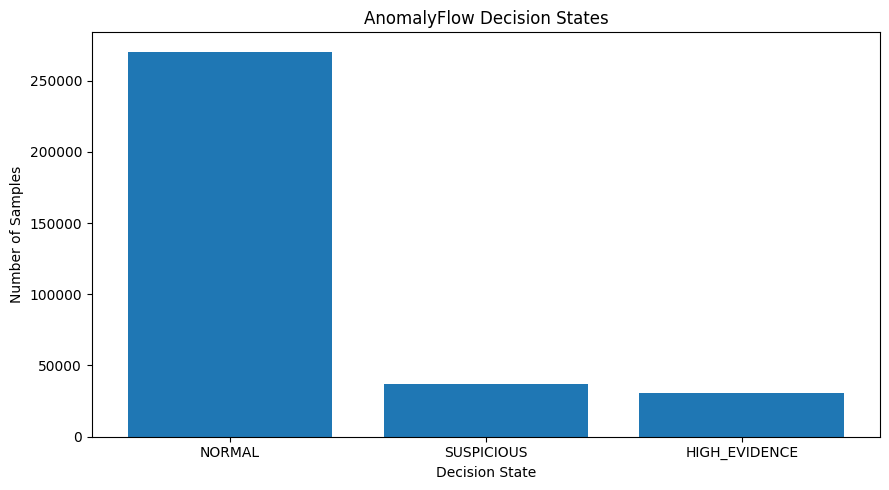


Chart generated successfully.
Decision states displayed:
 - NORMAL
 - SUSPICIOUS
 - HIGH_EVIDENCE


In [17]:
# ============================================================
# Section 3 — Dashboard Preview & Validation
# Cell 1 — Decision State Chart Preview
# ============================================================

print("=" * 80)
print("DECISION STATE CHART PREVIEW")
print("=" * 80)

decision_state_fig = plot_decision_state_chart()

plt.show()

print("\nChart generated successfully.")
print("Decision states displayed:")
print(" - NORMAL")
print(" - SUSPICIOUS")
print(" - HIGH_EVIDENCE")

SECURITY SEVERITY CHART PREVIEW


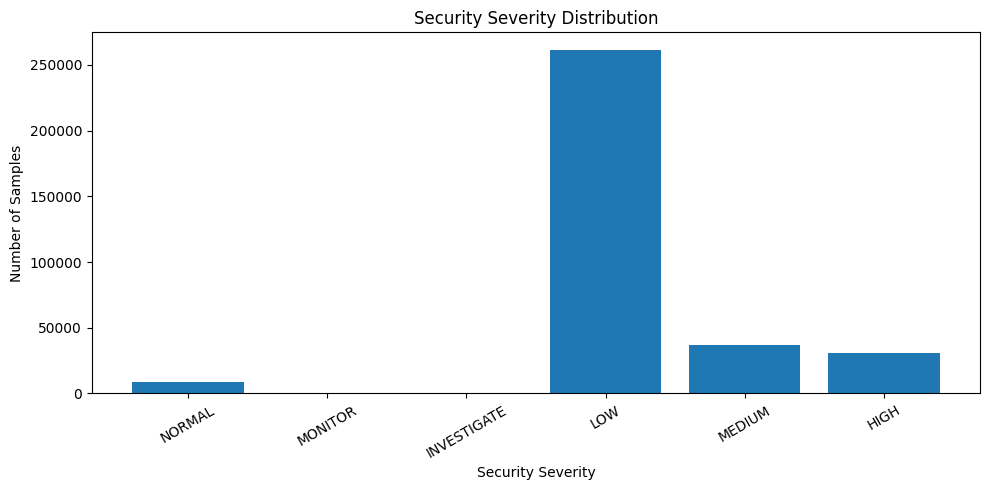


Chart generated successfully.
Security severity levels displayed:
 - NORMAL
 - MONITOR
 - INVESTIGATE
 - LOW
 - MEDIUM
 - HIGH


In [18]:
# ============================================================
# Section 3 — Dashboard Preview & Validation
# Cell 2 — Security Severity Chart Preview
# ============================================================

print("=" * 80)
print("SECURITY SEVERITY CHART PREVIEW")
print("=" * 80)

severity_fig = plot_security_severity_chart()

plt.show()

print("\nChart generated successfully.")
print("Security severity levels displayed:")
print(" - NORMAL")
print(" - MONITOR")
print(" - INVESTIGATE")
print(" - LOW")
print(" - MEDIUM")
print(" - HIGH")


MITIGATION ACTION CHART PREVIEW


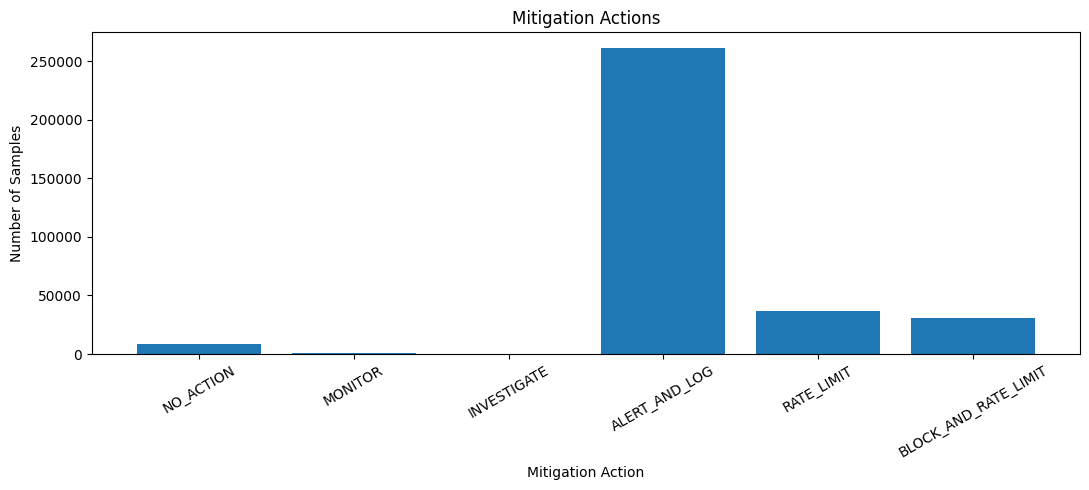


Chart generated successfully.
Mitigation actions displayed:
 - NO_ACTION
 - MONITOR
 - INVESTIGATE
 - ALERT_AND_LOG
 - RATE_LIMIT
 - BLOCK_AND_RATE_LIMIT


In [19]:
# ============================================================
# Section 3 — Dashboard Preview & Validation
# Cell 3 — Mitigation Action Chart Preview
# ============================================================

print("=" * 80)
print("MITIGATION ACTION CHART PREVIEW")
print("=" * 80)

mitigation_action_fig = plot_mitigation_action_chart()

plt.show()

print("\nChart generated successfully.")
print("Mitigation actions displayed:")
print(" - NO_ACTION")
print(" - MONITOR")
print(" - INVESTIGATE")
print(" - ALERT_AND_LOG")
print(" - RATE_LIMIT")
print(" - BLOCK_AND_RATE_LIMIT")

ATTACK DISTRIBUTION CHART PREVIEW


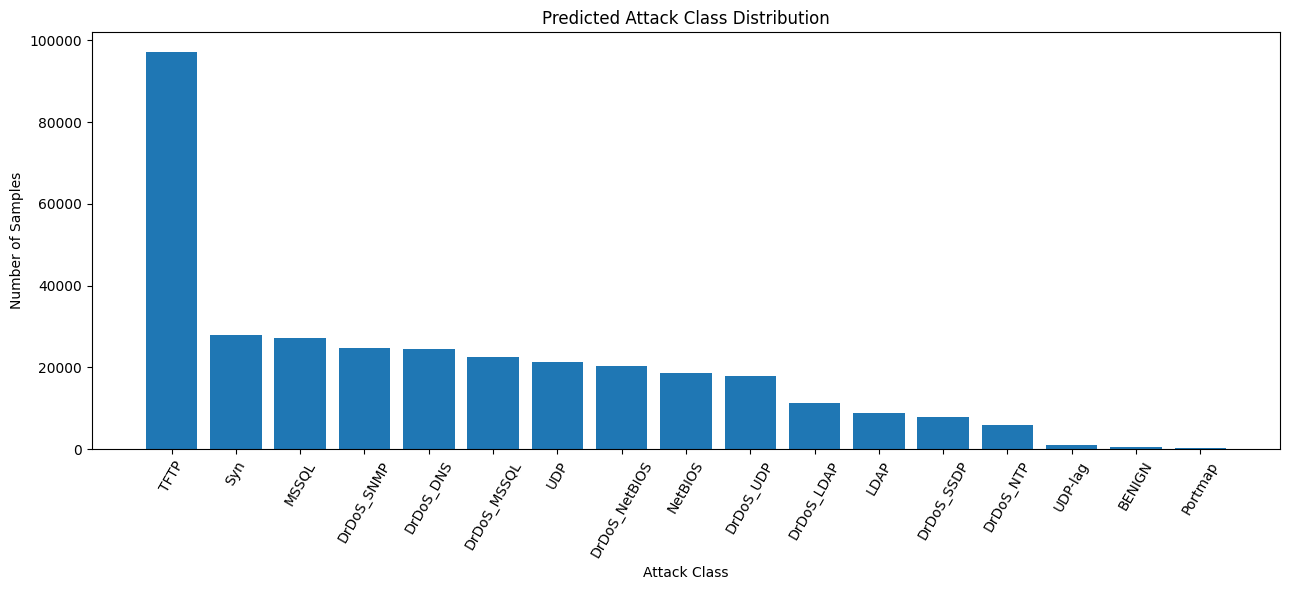


Chart generated successfully.
Total attack classes displayed: 17
Distribution source: Predicted_Label


In [20]:
# ============================================================
# Section 3 — Dashboard Preview & Validation
# Cell 4 — Attack Distribution Chart Preview
# ============================================================

print("=" * 80)
print("ATTACK DISTRIBUTION CHART PREVIEW")
print("=" * 80)

attack_distribution_fig = plot_attack_distribution()

plt.show()

print("\nChart generated successfully.")
print(f"Total attack classes displayed: {len(predicted_class_counts)}")
print("Distribution source: Predicted_Label")

ALERT TYPE CHART PREVIEW


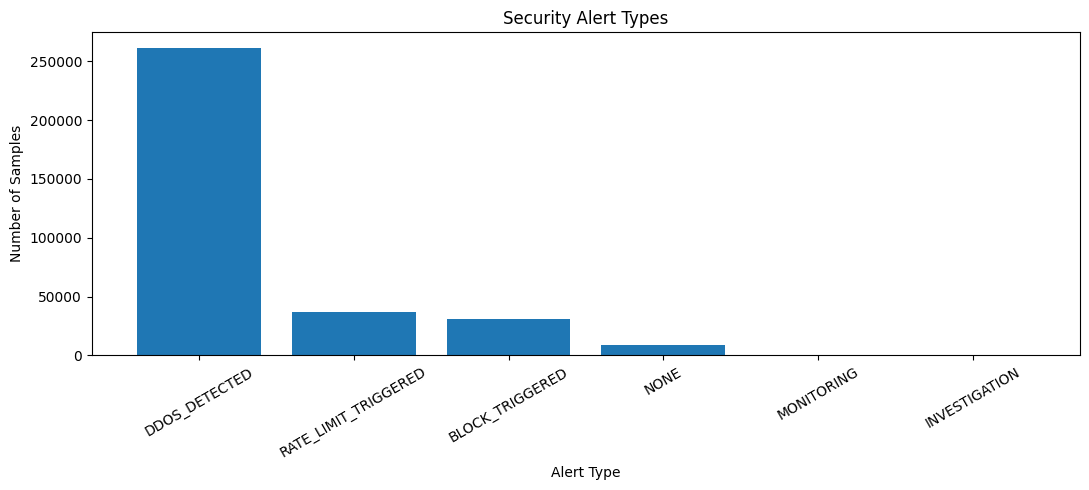


Chart generated successfully.
Total alert types displayed: 6
Distribution source: Alert_Type


In [21]:
# ============================================================
# Section 3 — Dashboard Preview & Validation
# Cell 5 — Alert Type Chart Preview
# ============================================================

print("=" * 80)
print("ALERT TYPE CHART PREVIEW")
print("=" * 80)

alert_type_fig = plot_alert_type_chart()

plt.show()

print("\nChart generated successfully.")
print(f"Total alert types displayed: {len(alert_type_counts)}")
print("Distribution source: Alert_Type")

MITIGATION OUTCOME CHART PREVIEW


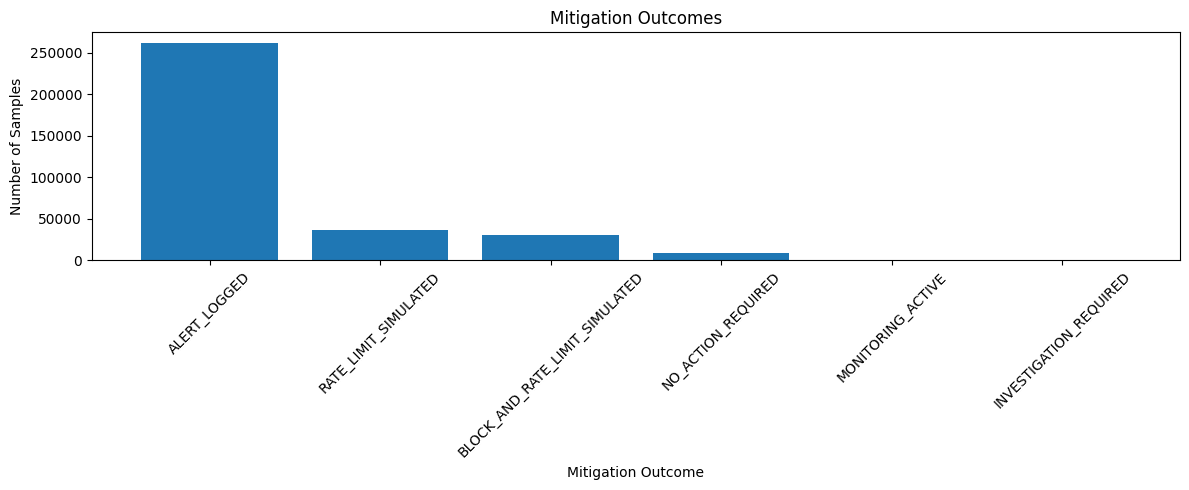


Chart generated successfully.
Total mitigation outcomes displayed: 6
Distribution source: Mitigation_Outcome


In [22]:
# ============================================================
# Section 3 — Dashboard Preview & Validation
# Cell 6 — Mitigation Outcome Chart Preview
# ============================================================

print("=" * 80)
print("MITIGATION OUTCOME CHART PREVIEW")
print("=" * 80)

mitigation_outcome_fig = plot_mitigation_outcome_chart()

plt.show()

print("\nChart generated successfully.")
print(
    f"Total mitigation outcomes displayed: "
    f"{len(mitigation_outcome_dashboard_df)}"
)
print("Distribution source: Mitigation_Outcome")

ANOMALYFLOW SCORE DISTRIBUTION PREVIEW


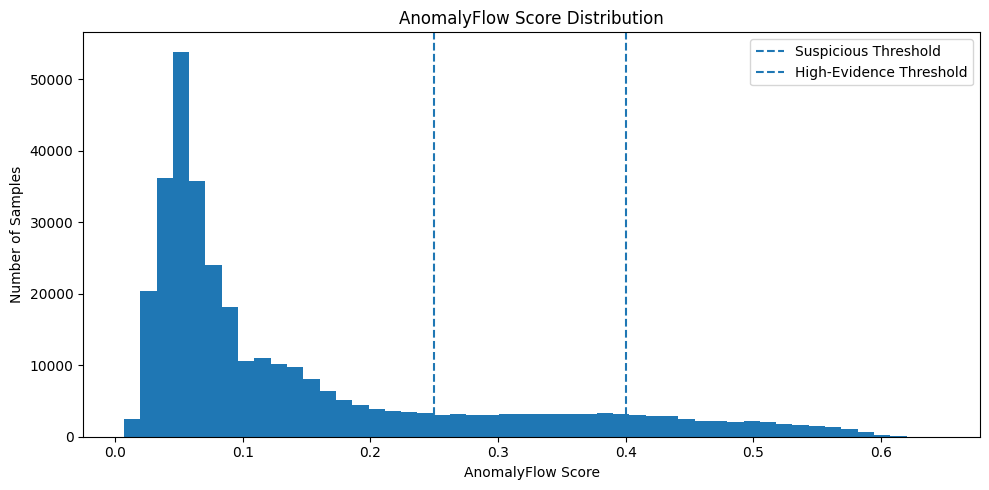


Chart generated successfully.
Mean AnomalyFlow Score   : 0.146910
Median AnomalyFlow Score : 0.081706
Low Threshold            : 0.25
High Threshold           : 0.4


In [23]:
# ============================================================
# Section 3 — Dashboard Preview & Validation
# Cell 7 — AnomalyFlow Score Distribution Preview
# ============================================================

print("=" * 80)
print("ANOMALYFLOW SCORE DISTRIBUTION PREVIEW")
print("=" * 80)

anomalyflow_score_fig = plot_anomalyflow_score_distribution()

plt.show()

print("\nChart generated successfully.")
print(f"Mean AnomalyFlow Score   : {mitigation_df['AnomalyFlow_Score'].mean():.6f}")
print(f"Median AnomalyFlow Score : {mitigation_df['AnomalyFlow_Score'].median():.6f}")
print(f"Low Threshold            : {anomalyflow_config['low_threshold']}")
print(f"High Threshold           : {anomalyflow_config['high_threshold']}")

MODEL CONFIDENCE DISTRIBUTION PREVIEW


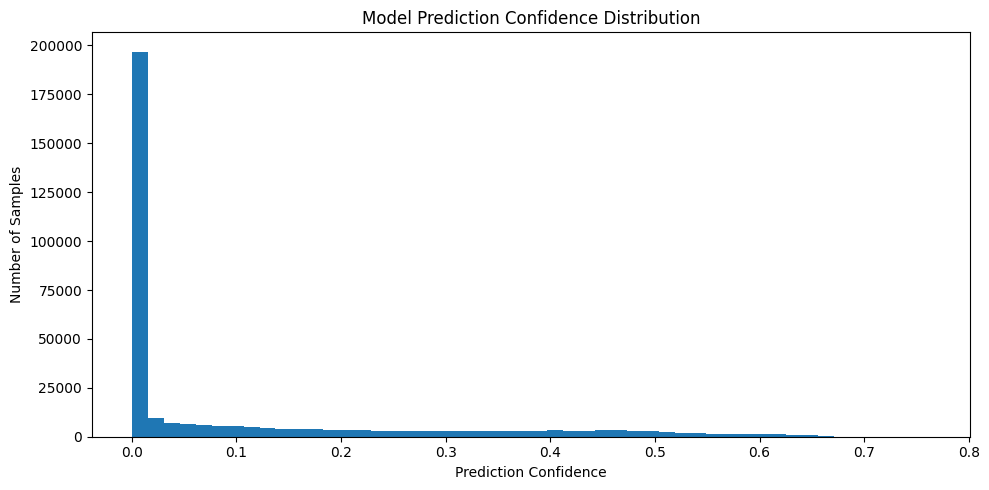


Chart generated successfully.
Mean Confidence   : 0.107423
Median Confidence : 0.000273
Minimum           : 0.000000
Maximum           : 0.762771


In [24]:
# ============================================================
# Section 3 — Dashboard Preview & Validation
# Cell 8 — Model Confidence Distribution Preview
# ============================================================

print("=" * 80)
print("MODEL CONFIDENCE DISTRIBUTION PREVIEW")
print("=" * 80)

confidence_fig = plot_confidence_distribution()

plt.show()

print("\nChart generated successfully.")
print(f"Mean Confidence   : {mitigation_df['Confidence'].mean():.6f}")
print(f"Median Confidence : {mitigation_df['Confidence'].median():.6f}")
print(f"Minimum           : {mitigation_df['Confidence'].min():.6f}")
print(f"Maximum           : {mitigation_df['Confidence'].max():.6f}")

RECENT SECURITY EVENTS PREVIEW


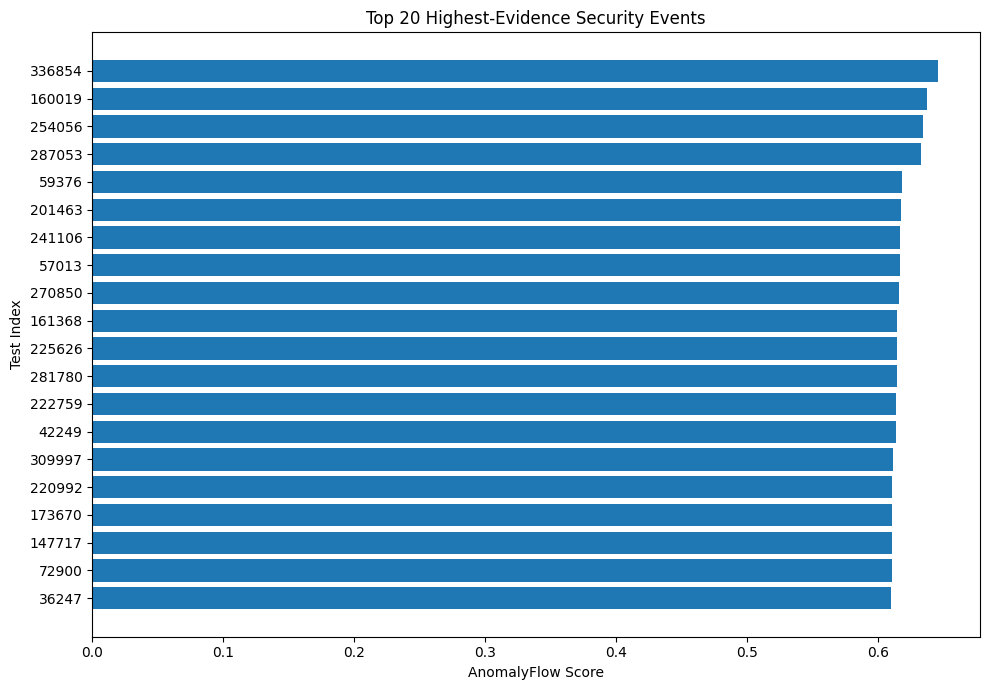


Chart generated successfully.
Events displayed : 20
Highest AnomalyFlow Score : 0.645689
Lowest AnomalyFlow Score in preview : 0.610256


In [25]:
# ============================================================
# Section 3 — Dashboard Preview & Validation
# Cell 9 — Recent Security Events Preview
# ============================================================

print("=" * 80)
print("RECENT SECURITY EVENTS PREVIEW")
print("=" * 80)

recent_events_fig = plot_recent_security_events()

plt.show()

print("\nChart generated successfully.")
print(f"Events displayed : {len(recent_events_top20)}")
print(
    f"Highest AnomalyFlow Score : "
    f"{recent_events_top20['AnomalyFlow_Score'].max():.6f}"
)
print(
    f"Lowest AnomalyFlow Score in preview : "
    f"{recent_events_top20['AnomalyFlow_Score'].min():.6f}"
)

In [26]:
# ============================================================
# Section 3 — Dashboard Preview & Validation
# Cell 10 — Complete Visualization Preview Verification
# ============================================================

print("=" * 80)
print("COMPLETE VISUALIZATION PREVIEW VERIFICATION")
print("=" * 80)

preview_objects = {
    "Decision State Chart": decision_state_fig,
    "Security Severity Chart": severity_fig,
    "Mitigation Action Chart": mitigation_action_fig,
    "Attack Distribution Chart": attack_distribution_fig,
    "Alert Type Chart": alert_type_fig,
    "Mitigation Outcome Chart": mitigation_outcome_fig,
    "AnomalyFlow Score Chart": anomalyflow_score_fig,
    "Confidence Distribution Chart": confidence_fig,
    "Recent Security Events Chart": recent_events_fig,
}

print("\nGenerated visualization objects:")

all_previews_available = True

for name, figure in preview_objects.items():
    available = figure is not None
    print(f"{name:<35}: {available}")
    all_previews_available = all_previews_available and available

print("\n" + "-" * 80)
print("PREVIEW VERIFICATION")
print("-" * 80)

print(f"\nTotal visualizations prepared : {len(preview_objects)}")
print(f"All visualizations available : {all_previews_available}")

print("\n" + "=" * 80)
print("VISUALIZATION PREVIEW VERIFICATION COMPLETE")
print("=" * 80)

COMPLETE VISUALIZATION PREVIEW VERIFICATION

Generated visualization objects:
Decision State Chart               : True
Security Severity Chart            : True
Mitigation Action Chart            : True
Attack Distribution Chart          : True
Alert Type Chart                   : True
Mitigation Outcome Chart           : True
AnomalyFlow Score Chart            : True
Confidence Distribution Chart      : True
Recent Security Events Chart       : True

--------------------------------------------------------------------------------
PREVIEW VERIFICATION
--------------------------------------------------------------------------------

Total visualizations prepared : 9
All visualizations available : True

VISUALIZATION PREVIEW VERIFICATION COMPLETE


# Section 4

In [28]:
# ============================================================
# Section 4 — Dashboard Application Preparation
# Cell 1 — Streamlit Environment Verification
# ============================================================

import importlib.util

print("=" * 80)
print("STREAMLIT ENVIRONMENT VERIFICATION")
print("=" * 80)

# ------------------------------------------------------------
# Check Streamlit installation
# ------------------------------------------------------------
streamlit_available = (
    importlib.util.find_spec("streamlit") is not None
)

print(f"\nStreamlit installed : {streamlit_available}")

# ------------------------------------------------------------
# Dashboard directory verification
# ------------------------------------------------------------
print("\nDashboard directory:")
print(DASHBOARD_DIR)

print(f"\nDashboard directory exists: {DASHBOARD_DIR.exists()}")

# ------------------------------------------------------------
# Current dashboard files
# ------------------------------------------------------------
dashboard_files = list(DASHBOARD_DIR.iterdir())

print("\nExisting dashboard files:")

if dashboard_files:
    for file_path in dashboard_files:
        print(f" - {file_path.name}")
else:
    print(" - None")

# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("STREAMLIT ENVIRONMENT VERIFICATION COMPLETE")
print("=" * 80)

print(f"\nStreamlit ready: {streamlit_available}")

STREAMLIT ENVIRONMENT VERIFICATION

Streamlit installed : False

Dashboard directory:
/content/drive/MyDrive/Major_Project/dashboard

Dashboard directory exists: True

Existing dashboard files:
 - None

STREAMLIT ENVIRONMENT VERIFICATION COMPLETE

Streamlit ready: False


In [29]:
# ============================================================
# Section 4 — Dashboard Application Preparation
# Cell 2 — Install Streamlit
# ============================================================

import subprocess
import sys
import importlib.util

print("=" * 80)
print("STREAMLIT INSTALLATION")
print("=" * 80)

# ------------------------------------------------------------
# Install Streamlit only if it is not already available
# ------------------------------------------------------------
if importlib.util.find_spec("streamlit") is None:

    print("\nStreamlit not found.")
    print("Installing Streamlit...")

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "streamlit",
        "-q"
    ])

    print("\nStreamlit installation completed.")

else:
    print("\nStreamlit is already installed.")

# ------------------------------------------------------------
# Verify installation
# ------------------------------------------------------------
streamlit_available = (
    importlib.util.find_spec("streamlit") is not None
)

print("\n" + "-" * 80)
print("INSTALLATION VERIFICATION")
print("-" * 80)

print(f"\nStreamlit installed : {streamlit_available}")

if streamlit_available:
    import streamlit
    print(f"Streamlit version   : {streamlit.__version__}")

print("\n" + "=" * 80)
print("STREAMLIT INSTALLATION COMPLETE")
print("=" * 80)

STREAMLIT INSTALLATION

Streamlit not found.
Installing Streamlit...

Streamlit installation completed.

--------------------------------------------------------------------------------
INSTALLATION VERIFICATION
--------------------------------------------------------------------------------

Streamlit installed : True
Streamlit version   : 1.62.0

STREAMLIT INSTALLATION COMPLETE


In [30]:
# ============================================================
# Section 4 — Dashboard Application Preparation
# Cell 3 — Create Streamlit Dashboard Application
# ============================================================

from pathlib import Path

print("=" * 80)
print("CREATING STREAMLIT DASHBOARD APPLICATION")
print("=" * 80)

# ------------------------------------------------------------
# Streamlit application path
# ------------------------------------------------------------
APP_PATH = DASHBOARD_DIR / "app.py"

# ------------------------------------------------------------
# Streamlit dashboard application
# ------------------------------------------------------------
dashboard_app_code = r'''
import streamlit as st
import pandas as pd
import json
from pathlib import Path
import matplotlib.pyplot as plt


# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path("/content/drive/MyDrive/Major_Project")

MITIGATION_RESULTS = (
    PROJECT_ROOT / "mitigation" / "final_mitigation_results.csv"
)

ANOMALYFLOW_CONFIG = (
    PROJECT_ROOT / "models" / "evaluation" / "anomalyflow_config.json"
)


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="AnomalyFlow Security Dashboard",
    page_icon="🛡️",
    layout="wide"
)


# ============================================================
# DATA LOADING
# ============================================================

@st.cache_data
def load_data():

    df = pd.read_csv(MITIGATION_RESULTS)

    with open(ANOMALYFLOW_CONFIG, "r") as f:
        config = json.load(f)

    return df, config


df, anomalyflow_config = load_data()


# ============================================================
# PAGE HEADER
# ============================================================

st.title("AnomalyFlow Security Dashboard")

st.caption(
    "Hybrid deep-learning and statistical network traffic "
    "analysis with automated security decision and mitigation simulation."
)


# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.header("Dashboard Controls")

severity_filter = st.sidebar.multiselect(
    "Security Severity",
    options=sorted(df["Security_Severity"].unique()),
    default=sorted(df["Security_Severity"].unique())
)

decision_filter = st.sidebar.multiselect(
    "Decision State",
    options=sorted(df["Decision_State"].unique()),
    default=sorted(df["Decision_State"].unique())
)

filtered_df = df[
    df["Security_Severity"].isin(severity_filter)
    & df["Decision_State"].isin(decision_filter)
]


# ============================================================
# KPI CALCULATIONS
# ============================================================

total_samples = len(filtered_df)

alerts_generated = int(
    filtered_df["Alert_Generated"].sum()
)

high_evidence = int(
    (filtered_df["Decision_State"] == "HIGH_EVIDENCE").sum()
)

simulated_blocks = int(
    filtered_df["Simulated_Block"].sum()
)

rate_limits = int(
    filtered_df["Simulated_Rate_Limit"].sum()
)

ddos_classes = {
    "DrDoS_DNS",
    "DrDoS_LDAP",
    "DrDoS_MSSQL",
    "DrDoS_NTP",
    "DrDoS_NetBIOS",
    "DrDoS_SNMP",
    "DrDoS_SSDP",
    "DrDoS_UDP",
    "LDAP",
    "MSSQL",
    "NetBIOS",
    "Portmap",
    "Syn",
    "TFTP",
    "UDP",
    "UDP-lag"
}

predicted_ddos = int(
    filtered_df["Predicted_Label"].isin(ddos_classes).sum()
)


# ============================================================
# KPI CARDS
# ============================================================

st.subheader("Security Overview")

col1, col2, col3, col4, col5, col6 = st.columns(6)

col1.metric(
    "Total Samples",
    f"{total_samples:,}"
)

col2.metric(
    "Predicted DDoS",
    f"{predicted_ddos:,}"
)

col3.metric(
    "Alerts Generated",
    f"{alerts_generated:,}"
)

col4.metric(
    "High Evidence",
    f"{high_evidence:,}"
)

col5.metric(
    "Simulated Blocks",
    f"{simulated_blocks:,}"
)

col6.metric(
    "Rate Limits",
    f"{rate_limits:,}"
)


# ============================================================
# DECISION STATE + SECURITY SEVERITY
# ============================================================

st.subheader("Security Decision Analysis")

col1, col2 = st.columns(2)


with col1:

    st.markdown("#### AnomalyFlow Decision States")

    decision_counts = (
        filtered_df["Decision_State"]
        .value_counts()
        .reindex(
            ["NORMAL", "SUSPICIOUS", "HIGH_EVIDENCE"],
            fill_value=0
        )
    )

    st.bar_chart(decision_counts)


with col2:

    st.markdown("#### Security Severity")

    severity_counts = (
        filtered_df["Security_Severity"]
        .value_counts()
    )

    st.bar_chart(severity_counts)


# ============================================================
# ATTACK DISTRIBUTION
# ============================================================

st.subheader("Predicted Attack Distribution")

attack_counts = (
    filtered_df["Predicted_Label"]
    .value_counts()
)

st.bar_chart(attack_counts)


# ============================================================
# MITIGATION ANALYSIS
# ============================================================

st.subheader("Mitigation Analysis")

col1, col2 = st.columns(2)


with col1:

    st.markdown("#### Mitigation Actions")

    mitigation_counts = (
        filtered_df["Mitigation_Action"]
        .value_counts()
    )

    st.bar_chart(mitigation_counts)


with col2:

    st.markdown("#### Alert Types")

    alert_counts = (
        filtered_df["Alert_Type"]
        .value_counts()
    )

    st.bar_chart(alert_counts)


# ============================================================
# ANOMALYFLOW SCORE DISTRIBUTION
# ============================================================

st.subheader("AnomalyFlow Score Distribution")

fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(
    filtered_df["AnomalyFlow_Score"],
    bins=50
)

ax.axvline(
    anomalyflow_config["low_threshold"],
    linestyle="--",
    label="Suspicious Threshold"
)

ax.axvline(
    anomalyflow_config["high_threshold"],
    linestyle="--",
    label="High-Evidence Threshold"
)

ax.set_xlabel("AnomalyFlow Score")
ax.set_ylabel("Number of Samples")
ax.set_title("AnomalyFlow Score Distribution")
ax.legend()

fig.tight_layout()

st.pyplot(fig)


# ============================================================
# HIGH-EVIDENCE SECURITY EVENTS
# ============================================================

st.subheader("Highest-Evidence Security Events")

event_columns = [
    "Test_Index",
    "Predicted_Label",
    "Confidence",
    "AnomalyFlow_Score",
    "Decision_State",
    "Security_Severity",
    "Mitigation_Action",
    "Alert_Level",
    "Alert_Type",
    "Mitigation_Outcome"
]

top_events = (
    filtered_df[event_columns]
    .sort_values(
        "AnomalyFlow_Score",
        ascending=False
    )
    .head(20)
)

st.dataframe(
    top_events,
    use_container_width=True,
    hide_index=True
)


# ============================================================
# ANOMALYFLOW CONFIGURATION
# ============================================================

with st.expander("AnomalyFlow Configuration"):

    config_col1, config_col2 = st.columns(2)

    config_col1.metric(
        "Confidence Weight",
        anomalyflow_config["confidence_weight"]
    )

    config_col2.metric(
        "Rényi Weight",
        anomalyflow_config["renyi_weight"]
    )

    config_col1.metric(
        "Low Threshold",
        anomalyflow_config["low_threshold"]
    )

    config_col2.metric(
        "High Threshold",
        anomalyflow_config["high_threshold"]
    )


# ============================================================
# FOOTER
# ============================================================

st.divider()

st.caption(
    "AnomalyFlow | Network Traffic Detection, Security Decision "
    "and Mitigation Simulation"
)
'''

# ------------------------------------------------------------
# Write application file
# ------------------------------------------------------------
with open(APP_PATH, "w", encoding="utf-8") as f:
    f.write(dashboard_app_code)

# ------------------------------------------------------------
# Verify application file
# ------------------------------------------------------------
print("\nDashboard application created:")
print(APP_PATH)

print("\nFile exists:", APP_PATH.exists())

if APP_PATH.exists():
    print("File size :", f"{APP_PATH.stat().st_size:,} bytes")

print("\n" + "=" * 80)
print("STREAMLIT DASHBOARD APPLICATION CREATED")
print("=" * 80)

CREATING STREAMLIT DASHBOARD APPLICATION

Dashboard application created:
/content/drive/MyDrive/Major_Project/dashboard/app.py

File exists: True
File size : 7,436 bytes

STREAMLIT DASHBOARD APPLICATION CREATED


In [31]:
# ============================================================
# Section 4 — Dashboard Application Preparation
# Cell 4 — Streamlit Application Syntax Verification
# ============================================================

import py_compile

print("=" * 80)
print("STREAMLIT APPLICATION SYNTAX VERIFICATION")
print("=" * 80)

syntax_check_pass = True

try:
    py_compile.compile(
        str(APP_PATH),
        doraise=True
    )

    print("\nSyntax check : PASS")
    print("Application contains no Python syntax errors.")

except Exception as e:
    syntax_check_pass = False

    print("\nSyntax check : FAIL")
    print("\nError:")
    print(e)

print("\n" + "-" * 80)
print("APPLICATION VERIFICATION")
print("-" * 80)

print(f"\nApplication path : {APP_PATH}")
print(f"File exists      : {APP_PATH.exists()}")
print(f"Syntax PASS      : {syntax_check_pass}")

print("\n" + "=" * 80)
print("STREAMLIT APPLICATION SYNTAX VERIFICATION COMPLETE")
print("=" * 80)

STREAMLIT APPLICATION SYNTAX VERIFICATION

Syntax check : PASS
Application contains no Python syntax errors.

--------------------------------------------------------------------------------
APPLICATION VERIFICATION
--------------------------------------------------------------------------------

Application path : /content/drive/MyDrive/Major_Project/dashboard/app.py
File exists      : True
Syntax PASS      : True

STREAMLIT APPLICATION SYNTAX VERIFICATION COMPLETE


In [32]:
# ============================================================
# Section 4 — Dashboard Application Preparation
# Cell 5 — Dashboard Application Artifact Verification
# ============================================================

print("=" * 80)
print("DASHBOARD APPLICATION ARTIFACT VERIFICATION")
print("=" * 80)

# ------------------------------------------------------------
# Verify application file
# ------------------------------------------------------------
app_exists = APP_PATH.exists()

# ------------------------------------------------------------
# Verify required dashboard artifacts
# ------------------------------------------------------------
required_artifacts = {
    "Streamlit Application": APP_PATH,
    "Mitigation Results": MITIGATION_RESULTS,
    "AnomalyFlow Configuration": ANOMALYFLOW_CONFIG,
}

artifact_results = {}

print("\nRequired dashboard artifacts:")

for name, path in required_artifacts.items():

    exists = path.exists()

    artifact_results[name] = exists

    print(f"{name:<30}: {exists}")
    print(f"  Path: {path}")

# ------------------------------------------------------------
# Verify application file size
# ------------------------------------------------------------
app_size = APP_PATH.stat().st_size if app_exists else 0

print("\n" + "-" * 80)
print("APPLICATION DETAILS")
print("-" * 80)

print(f"\nApplication path : {APP_PATH}")
print(f"File exists      : {app_exists}")
print(f"File size        : {app_size:,} bytes")

# ------------------------------------------------------------
# Overall verification
# ------------------------------------------------------------
all_artifacts_available = all(
    artifact_results.values()
)

print("\n" + "-" * 80)
print("OVERALL ARTIFACT VERIFICATION")
print("-" * 80)

print(
    f"\nAll required artifacts available: "
    f"{all_artifacts_available}"
)

print("\n" + "=" * 80)
print("DASHBOARD APPLICATION ARTIFACT VERIFICATION COMPLETE")
print("=" * 80)

DASHBOARD APPLICATION ARTIFACT VERIFICATION

Required dashboard artifacts:
Streamlit Application         : True
  Path: /content/drive/MyDrive/Major_Project/dashboard/app.py
Mitigation Results            : True
  Path: /content/drive/MyDrive/Major_Project/mitigation/final_mitigation_results.csv
AnomalyFlow Configuration     : True
  Path: /content/drive/MyDrive/Major_Project/models/evaluation/anomalyflow_config.json

--------------------------------------------------------------------------------
APPLICATION DETAILS
--------------------------------------------------------------------------------

Application path : /content/drive/MyDrive/Major_Project/dashboard/app.py
File exists      : True
File size        : 7,436 bytes

--------------------------------------------------------------------------------
OVERALL ARTIFACT VERIFICATION
--------------------------------------------------------------------------------

All required artifacts available: True

DASHBOARD APPLICATION ARTIFACT VER

# Section 5

In [33]:
# ============================================================
# Section 5 — Dashboard Testing & Launch
# Cell 1 — Streamlit Application Runtime Test
# ============================================================

import subprocess
import time
import requests
import os

print("=" * 80)
print("STREAMLIT APPLICATION RUNTIME TEST")
print("=" * 80)

# ------------------------------------------------------------
# Streamlit server configuration
# ------------------------------------------------------------
STREAMLIT_PORT = 8501

streamlit_command = [
    "streamlit",
    "run",
    str(APP_PATH),
    "--server.port",
    str(STREAMLIT_PORT),
    "--server.address",
    "0.0.0.0",
    "--server.headless",
    "true",
    "--browser.gatherUsageStats",
    "false"
]

print("\nStarting Streamlit application...")

# ------------------------------------------------------------
# Start Streamlit process
# ------------------------------------------------------------
streamlit_process = subprocess.Popen(
    streamlit_command,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

# ------------------------------------------------------------
# Wait for server startup
# ------------------------------------------------------------
time.sleep(8)

# ------------------------------------------------------------
# Check process status
# ------------------------------------------------------------
process_running = (
    streamlit_process.poll() is None
)

print(f"\nStreamlit process running: {process_running}")

# ------------------------------------------------------------
# Check local HTTP response
# ------------------------------------------------------------
server_reachable = False

try:
    response = requests.get(
        f"http://127.0.0.1:{STREAMLIT_PORT}",
        timeout=10
    )

    server_reachable = response.status_code == 200

    print(f"HTTP status code       : {response.status_code}")
    print(f"Server reachable       : {server_reachable}")

except Exception as e:
    print("\nServer connection check failed:")
    print(e)

# ------------------------------------------------------------
# Final runtime verification
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("RUNTIME VERIFICATION")
print("-" * 80)

runtime_test_pass = (
    process_running and server_reachable
)

print(f"\nProcess running : {process_running}")
print(f"Server reachable: {server_reachable}")
print(f"Runtime PASS    : {runtime_test_pass}")

print("\n" + "=" * 80)
print("STREAMLIT APPLICATION RUNTIME TEST COMPLETE")
print("=" * 80)

STREAMLIT APPLICATION RUNTIME TEST

Starting Streamlit application...

Streamlit process running: True
HTTP status code       : 200
Server reachable       : True

--------------------------------------------------------------------------------
RUNTIME VERIFICATION
--------------------------------------------------------------------------------

Process running : True
Server reachable: True
Runtime PASS    : True

STREAMLIT APPLICATION RUNTIME TEST COMPLETE


In [34]:
# ============================================================
# Section 5 — Dashboard Testing & Launch
# Cell 2 — Create Portable Local Configuration
# ============================================================

print("=" * 80)
print("CREATING PORTABLE DASHBOARD CONFIGURATION")
print("=" * 80)

# ------------------------------------------------------------
# Local dashboard configuration
# ------------------------------------------------------------
DASHBOARD_CONFIG_PATH = DASHBOARD_DIR / "dashboard_config.json"

dashboard_config = {
    "project_root": "..",
    "mitigation_results": "../mitigation/final_mitigation_results.csv",
    "anomalyflow_config": "../models/evaluation/anomalyflow_config.json"
}

with open(DASHBOARD_CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(
        dashboard_config,
        f,
        indent=4
    )

print("\nConfiguration created:")
print(DASHBOARD_CONFIG_PATH)

print("\nConfiguration contents:")
print(
    json.dumps(
        dashboard_config,
        indent=4
    )
)

print("\n" + "-" * 80)
print("CONFIGURATION VERIFICATION")
print("-" * 80)

print(
    f"\nFile exists : "
    f"{DASHBOARD_CONFIG_PATH.exists()}"
)

if DASHBOARD_CONFIG_PATH.exists():
    print(
        f"File size  : "
        f"{DASHBOARD_CONFIG_PATH.stat().st_size:,} bytes"
    )

print("\n" + "=" * 80)
print("PORTABLE DASHBOARD CONFIGURATION CREATED")
print("=" * 80)

CREATING PORTABLE DASHBOARD CONFIGURATION

Configuration created:
/content/drive/MyDrive/Major_Project/dashboard/dashboard_config.json

Configuration contents:
{
    "project_root": "..",
    "mitigation_results": "../mitigation/final_mitigation_results.csv",
    "anomalyflow_config": "../models/evaluation/anomalyflow_config.json"
}

--------------------------------------------------------------------------------
CONFIGURATION VERIFICATION
--------------------------------------------------------------------------------

File exists : True
File size  : 174 bytes

PORTABLE DASHBOARD CONFIGURATION CREATED


In [35]:
# ============================================================
# Section 5 — Dashboard Testing & Launch
# Cell 3 — Update Dashboard for Portable Paths
# ============================================================

print("=" * 80)
print("UPDATING DASHBOARD FOR PORTABLE PATHS")
print("=" * 80)

# ------------------------------------------------------------
# Portable Streamlit application
# ------------------------------------------------------------
portable_dashboard_app_code = r'''
import streamlit as st
import pandas as pd
import json
from pathlib import Path
import matplotlib.pyplot as plt


# ============================================================
# PROJECT PATHS
# ============================================================

DASHBOARD_DIR = Path(__file__).resolve().parent
PROJECT_ROOT = DASHBOARD_DIR.parent

CONFIG_PATH = DASHBOARD_DIR / "dashboard_config.json"


# ============================================================
# LOAD CONFIGURATION
# ============================================================

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    dashboard_config = json.load(f)


MITIGATION_RESULTS = (
    DASHBOARD_DIR / dashboard_config["mitigation_results"]
).resolve()

ANOMALYFLOW_CONFIG = (
    DASHBOARD_DIR / dashboard_config["anomalyflow_config"]
).resolve()


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="AnomalyFlow Security Dashboard",
    page_icon="🛡️",
    layout="wide"
)


# ============================================================
# DATA LOADING
# ============================================================

@st.cache_data
def load_data():

    df = pd.read_csv(MITIGATION_RESULTS)

    with open(ANOMALYFLOW_CONFIG, "r", encoding="utf-8") as f:
        config = json.load(f)

    return df, config


df, anomalyflow_config = load_data()


# ============================================================
# PAGE HEADER
# ============================================================

st.title("AnomalyFlow Security Dashboard")

st.caption(
    "Hybrid deep-learning and statistical network traffic "
    "analysis with automated security decision and mitigation simulation."
)


# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.header("Dashboard Controls")

severity_filter = st.sidebar.multiselect(
    "Security Severity",
    options=sorted(df["Security_Severity"].unique()),
    default=sorted(df["Security_Severity"].unique())
)

decision_filter = st.sidebar.multiselect(
    "Decision State",
    options=sorted(df["Decision_State"].unique()),
    default=sorted(df["Decision_State"].unique())
)

filtered_df = df[
    df["Security_Severity"].isin(severity_filter)
    & df["Decision_State"].isin(decision_filter)
]


# ============================================================
# KPI CALCULATIONS
# ============================================================

total_samples = len(filtered_df)

alerts_generated = int(
    filtered_df["Alert_Generated"].sum()
)

high_evidence = int(
    (filtered_df["Decision_State"] == "HIGH_EVIDENCE").sum()
)

simulated_blocks = int(
    filtered_df["Simulated_Block"].sum()
)

rate_limits = int(
    filtered_df["Simulated_Rate_Limit"].sum()
)

ddos_classes = {
    "DrDoS_DNS",
    "DrDoS_LDAP",
    "DrDoS_MSSQL",
    "DrDoS_NTP",
    "DrDoS_NetBIOS",
    "DrDoS_SNMP",
    "DrDoS_SSDP",
    "DrDoS_UDP",
    "LDAP",
    "MSSQL",
    "NetBIOS",
    "Portmap",
    "Syn",
    "TFTP",
    "UDP",
    "UDP-lag"
}

predicted_ddos = int(
    filtered_df["Predicted_Label"].isin(ddos_classes).sum()
)


# ============================================================
# KPI CARDS
# ============================================================

st.subheader("Security Overview")

col1, col2, col3, col4, col5, col6 = st.columns(6)

col1.metric("Total Samples", f"{total_samples:,}")
col2.metric("Predicted DDoS", f"{predicted_ddos:,}")
col3.metric("Alerts Generated", f"{alerts_generated:,}")
col4.metric("High Evidence", f"{high_evidence:,}")
col5.metric("Simulated Blocks", f"{simulated_blocks:,}")
col6.metric("Rate Limits", f"{rate_limits:,}")


# ============================================================
# DECISION STATE + SECURITY SEVERITY
# ============================================================

st.subheader("Security Decision Analysis")

col1, col2 = st.columns(2)

with col1:

    st.markdown("#### AnomalyFlow Decision States")

    decision_counts = (
        filtered_df["Decision_State"]
        .value_counts()
        .reindex(
            ["NORMAL", "SUSPICIOUS", "HIGH_EVIDENCE"],
            fill_value=0
        )
    )

    st.bar_chart(decision_counts)


with col2:

    st.markdown("#### Security Severity")

    severity_counts = (
        filtered_df["Security_Severity"]
        .value_counts()
    )

    st.bar_chart(severity_counts)


# ============================================================
# ATTACK DISTRIBUTION
# ============================================================

st.subheader("Predicted Attack Distribution")

attack_counts = (
    filtered_df["Predicted_Label"]
    .value_counts()
)

st.bar_chart(attack_counts)


# ============================================================
# MITIGATION ANALYSIS
# ============================================================

st.subheader("Mitigation Analysis")

col1, col2 = st.columns(2)

with col1:

    st.markdown("#### Mitigation Actions")

    mitigation_counts = (
        filtered_df["Mitigation_Action"]
        .value_counts()
    )

    st.bar_chart(mitigation_counts)


with col2:

    st.markdown("#### Alert Types")

    alert_counts = (
        filtered_df["Alert_Type"]
        .value_counts()
    )

    st.bar_chart(alert_counts)


# ============================================================
# ANOMALYFLOW SCORE DISTRIBUTION
# ============================================================

st.subheader("AnomalyFlow Score Distribution")

fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(
    filtered_df["AnomalyFlow_Score"],
    bins=50
)

ax.axvline(
    anomalyflow_config["low_threshold"],
    linestyle="--",
    label="Suspicious Threshold"
)

ax.axvline(
    anomalyflow_config["high_threshold"],
    linestyle="--",
    label="High-Evidence Threshold"
)

ax.set_xlabel("AnomalyFlow Score")
ax.set_ylabel("Number of Samples")
ax.set_title("AnomalyFlow Score Distribution")
ax.legend()

fig.tight_layout()

st.pyplot(fig)


# ============================================================
# HIGH-EVIDENCE SECURITY EVENTS
# ============================================================

st.subheader("Highest-Evidence Security Events")

event_columns = [
    "Test_Index",
    "Predicted_Label",
    "Confidence",
    "AnomalyFlow_Score",
    "Decision_State",
    "Security_Severity",
    "Mitigation_Action",
    "Alert_Level",
    "Alert_Type",
    "Mitigation_Outcome"
]

top_events = (
    filtered_df[event_columns]
    .sort_values(
        "AnomalyFlow_Score",
        ascending=False
    )
    .head(20)
)

st.dataframe(
    top_events,
    use_container_width=True,
    hide_index=True
)


# ============================================================
# ANOMALYFLOW CONFIGURATION
# ============================================================

with st.expander("AnomalyFlow Configuration"):

    config_col1, config_col2 = st.columns(2)

    config_col1.metric(
        "Confidence Weight",
        anomalyflow_config["confidence_weight"]
    )

    config_col2.metric(
        "Rényi Weight",
        anomalyflow_config["renyi_weight"]
    )

    config_col1.metric(
        "Low Threshold",
        anomalyflow_config["low_threshold"]
    )

    config_col2.metric(
        "High Threshold",
        anomalyflow_config["high_threshold"]
    )


# ============================================================
# FOOTER
# ============================================================

st.divider()

st.caption(
    "AnomalyFlow | Network Traffic Detection, Security Decision "
    "and Mitigation Simulation"
)
'''

# ------------------------------------------------------------
# Write updated application
# ------------------------------------------------------------
with open(APP_PATH, "w", encoding="utf-8") as f:
    f.write(portable_dashboard_app_code)

print("\nUpdated application:")
print(APP_PATH)

print("\nFile exists:", APP_PATH.exists())

if APP_PATH.exists():
    print("File size :", f"{APP_PATH.stat().st_size:,} bytes")

print("\n" + "=" * 80)
print("PORTABLE DASHBOARD APPLICATION CREATED")
print("=" * 80)

UPDATING DASHBOARD FOR PORTABLE PATHS

Updated application:
/content/drive/MyDrive/Major_Project/dashboard/app.py

File exists: True
File size : 7,707 bytes

PORTABLE DASHBOARD APPLICATION CREATED


In [36]:
# ============================================================
# Section 5 — Dashboard Testing & Launch
# Cell 4 — Portable Application Syntax Verification
# ============================================================

import py_compile

print("=" * 80)
print("PORTABLE APPLICATION SYNTAX VERIFICATION")
print("=" * 80)

syntax_check_pass = True

try:
    py_compile.compile(
        str(APP_PATH),
        doraise=True
    )

    print("\nSyntax check : PASS")
    print("Portable dashboard application contains no syntax errors.")

except Exception as e:
    syntax_check_pass = False

    print("\nSyntax check : FAIL")
    print("\nError:")
    print(e)

print("\n" + "-" * 80)
print("PORTABLE APPLICATION VERIFICATION")
print("-" * 80)

print(f"\nApplication path : {APP_PATH}")
print(f"File exists      : {APP_PATH.exists()}")
print(f"Syntax PASS      : {syntax_check_pass}")

print("\n" + "=" * 80)
print("PORTABLE APPLICATION SYNTAX VERIFICATION COMPLETE")
print("=" * 80)


PORTABLE APPLICATION SYNTAX VERIFICATION

Syntax check : PASS
Portable dashboard application contains no syntax errors.

--------------------------------------------------------------------------------
PORTABLE APPLICATION VERIFICATION
--------------------------------------------------------------------------------

Application path : /content/drive/MyDrive/Major_Project/dashboard/app.py
File exists      : True
Syntax PASS      : True

PORTABLE APPLICATION SYNTAX VERIFICATION COMPLETE


In [38]:
# ============================================================
# Section 5 — Dashboard Testing & Launch
# Cell 5 — Portable Dashboard Runtime Test
# ============================================================

import subprocess
import time
import requests

print("=" * 80)
print("PORTABLE DASHBOARD RUNTIME TEST")
print("=" * 80)

# ------------------------------------------------------------
# Portable Streamlit server configuration
# ------------------------------------------------------------
PORTABLE_STREAMLIT_PORT = 8502

portable_streamlit_command = [
    "streamlit",
    "run",
    str(APP_PATH),
    "--server.port",
    str(PORTABLE_STREAMLIT_PORT),
    "--server.address",
    "0.0.0.0",
    "--server.headless",
    "true",
    "--browser.gatherUsageStats",
    "false"
]

print("\nStarting portable Streamlit application...")

portable_streamlit_process = subprocess.Popen(
    portable_streamlit_command,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

# ------------------------------------------------------------
# Wait for startup
# ------------------------------------------------------------
time.sleep(8)

# ------------------------------------------------------------
# Process verification
# ------------------------------------------------------------
portable_process_running = (
    portable_streamlit_process.poll() is None
)

print(
    f"\nStreamlit process running: "
    f"{portable_process_running}"
)

# ------------------------------------------------------------
# HTTP verification
# ------------------------------------------------------------
portable_server_reachable = False

try:
    response = requests.get(
        f"http://127.0.0.1:{PORTABLE_STREAMLIT_PORT}",
        timeout=10
    )

    portable_server_reachable = (
        response.status_code == 200
    )

    print(
        f"HTTP status code       : "
        f"{response.status_code}"
    )

    print(
        f"Server reachable       : "
        f"{portable_server_reachable}"
    )

except Exception as e:

    print("\nServer connection check failed:")
    print(e)

# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("PORTABLE RUNTIME VERIFICATION")
print("-" * 80)

portable_runtime_pass = (
    portable_process_running
    and portable_server_reachable
)

print(
    f"\nProcess running : "
    f"{portable_process_running}"
)

print(
    f"Server reachable: "
    f"{portable_server_reachable}"
)

print(
    f"Runtime PASS    : "
    f"{portable_runtime_pass}"
)

print("\n" + "=" * 80)
print("PORTABLE DASHBOARD RUNTIME TEST COMPLETE")
print("=" * 80)

PORTABLE DASHBOARD RUNTIME TEST

Starting portable Streamlit application...

Streamlit process running: True
HTTP status code       : 200
Server reachable       : True

--------------------------------------------------------------------------------
PORTABLE RUNTIME VERIFICATION
--------------------------------------------------------------------------------

Process running : True
Server reachable: True
Runtime PASS    : True

PORTABLE DASHBOARD RUNTIME TEST COMPLETE


In [39]:
# ============================================================
# Section 5 — Dashboard Testing & Launch
# Cell 6 — Final Dashboard Artifact Verification
# ============================================================

print("=" * 80)
print("FINAL DASHBOARD ARTIFACT VERIFICATION")
print("=" * 80)

# ------------------------------------------------------------
# Final dashboard artifacts
# ------------------------------------------------------------
final_dashboard_artifacts = {
    "Streamlit Application": APP_PATH,
    "Dashboard Configuration": DASHBOARD_CONFIG_PATH,
    "Mitigation Results": MITIGATION_RESULTS,
    "AnomalyFlow Configuration": ANOMALYFLOW_CONFIG,
}

verification_results = {}

print("\nRequired dashboard artifacts:")

for name, path in final_dashboard_artifacts.items():

    exists = path.exists()

    verification_results[name] = exists

    print(f"\n{name}")
    print(f" Path   : {path}")
    print(f" Exists : {exists}")

    if exists:
        print(
            f" Size   : "
            f"{path.stat().st_size:,} bytes"
        )

# ------------------------------------------------------------
# Dataset verification
# ------------------------------------------------------------
dataset_rows = len(mitigation_df)

dataset_verification = (
    dataset_rows == EXPECTED_ROWS
)

# ------------------------------------------------------------
# Runtime verification
# ------------------------------------------------------------
runtime_verification = (
    portable_process_running
    and portable_server_reachable
)

# ------------------------------------------------------------
# Overall verification
# ------------------------------------------------------------
artifacts_verified = all(
    verification_results.values()
)

final_dashboard_pass = all([
    artifacts_verified,
    dataset_verification,
    runtime_verification
])

print("\n" + "-" * 80)
print("FINAL DASHBOARD VERIFICATION")
print("-" * 80)

print(
    f"\nDashboard artifacts verified : "
    f"{artifacts_verified}"
)

print(
    f"Dataset rows verified       : "
    f"{dataset_verification}"
)

print(
    f"Portable runtime verified   : "
    f"{runtime_verification}"
)

print(
    f"\nFINAL DASHBOARD PASS        : "
    f"{final_dashboard_pass}"
)

print("\n" + "=" * 80)
print("NOTEBOOK 08 DASHBOARD VERIFICATION COMPLETE")
print("=" * 80)


FINAL DASHBOARD ARTIFACT VERIFICATION

Required dashboard artifacts:

Streamlit Application
 Path   : /content/drive/MyDrive/Major_Project/dashboard/app.py
 Exists : True
 Size   : 7,707 bytes

Dashboard Configuration
 Path   : /content/drive/MyDrive/Major_Project/dashboard/dashboard_config.json
 Exists : True
 Size   : 174 bytes

Mitigation Results
 Path   : /content/drive/MyDrive/Major_Project/mitigation/final_mitigation_results.csv
 Exists : True
 Size   : 105,007,868 bytes

AnomalyFlow Configuration
 Path   : /content/drive/MyDrive/Major_Project/models/evaluation/anomalyflow_config.json
 Exists : True
 Size   : 223 bytes

--------------------------------------------------------------------------------
FINAL DASHBOARD VERIFICATION
--------------------------------------------------------------------------------

Dashboard artifacts verified : True
Dataset rows verified       : True
Portable runtime verified   : True

FINAL DASHBOARD PASS        : True

NOTEBOOK 08 DASHBOARD VERIFICAT